# 01 – Occlusion-aware 3D vegetation-structure label fusion (Table 3 workflow)

This notebook implements the **occlusion-aware 3D vegetation-structure label fusion workflow** (Table 3) to fuse:
- **LiDAR geometry** (XYZ + $Z_{\mathrm{norm}}$), and
- **2D structure labels** (classes 64–68) derived from UAS imagery / masks,

into a **gap-aware, biologically consistent 3D structure dataset** suitable for downstream 3D learning (sparse CNNs / transformers).

**Workflow stages (Table 3)**  
0. Inputs & configuration  
1. Class-specific height thresholding → per-class $Z_{\mathrm{norm}}$ priors  
2. Cartesian voxel-based label transfer → baseline 3D structure labels  
3. Mallee crown detection & instance assignment → `treeID` support  
4. Crown-centric polar refinement with height priors → occlusion-aware refinement  
5. Height-based consolidation & crown-level consistency → final structure labels + validated `treeID`s  
6. Output generation → analysis-ready 3D products (LAS + derived masks)

---

> Tip: Run the notebook top-to-bottom once, then revisit **Stage 4–5** with a few example crowns for qualitative QC.

**Workflow stages (Table 3)**  
Stage 0 (Inputs & configuration): load point cloud + 2D labels, set class IDs / parameters, and prepare output paths.

| Stage | Purpose | Key operations / rules | Output |
|---:|---|---|---|
| **1. Class height thresholding** | Derive robust vertical priors for each vegetation class (64–68) | XY nearest-neighbour matching (≤ 0.30 m) between 2D labels and LiDAR points<br>Outlier removal using P5–P95<br>Stratification using P15–P85 quantiles<br>Fallback to literature-derived defaults when $n < 20$ | Class-specific $Z_{\mathrm{norm}}$ height ranges |
| **2. Cartesian voxel-based label transfer** | Establish a stable baseline classification under irregular sampling | Joint discretisation into a 3D voxel grid (10 cm)<br>Majority voting within voxels<br>Transfer of voxel labels to $Z_{\mathrm{norm}}$ points | Baseline 3D structure labels |
| **3. Mallee crown detection & instance assignment** | Introduce object-level context for refinement | CHM construction from Mallee points<br>Gaussian smoothing<br>Watershed segmentation<br>Assignment of per-point crown identifier (`treeID` instances) | Detected Mallee crowns and crown instances (`treeID`s) |
| **4. Crown-centric polar refinement with height priors** | Resolve occlusion/overlap using local tree geometry and radial symmetry (mixed classes) | Local cylindrical coordinate transform $(r,\,\theta,\,Z_{\mathrm{norm}})$<br>Polar binning (0.10 m radial, 10° angular)<br>Local class probability voting<br>Height-prior modulation (P15–P85)<br>Conservative label updating (`min_conf = 0.3`, flip ratio = 1.5) | Crown-refined structure labels |
| **5. Height-based consolidation & crown-level consistency enforcement** | Finalise biologically coherent structure labels + valid crown instances | Merge woody debris (65) → Mallee (68) if $Z_{\mathrm{norm}} > 0.5$ m; remove low woody debris<br>Retain/promote unlabelled points if $Z_{\mathrm{norm}} \ge 1.3$ m<br>Crown-level majority voting (> 50% Mallee → Class 68)<br>Finalise valid Mallee `treeID`s | Final structure labels and validated `treeID`s |
| **6. Output generation** | Produce analysis-ready 3D products | Export LAS 1.4 (Point Format 6)<br>Generate full fused point cloud (gap-aware)<br>Generate vegetation-only mask product | Final 3D vegetation structure datasets |

---

> Tip: Run the notebook top-to-bottom once, then revisit **Stage 4–5** with a few example crowns for qualitative QC.

In [1]:
# Notebook setup: ensure local package imports resolve
import sys
from pathlib import Path

STEP_DIR = Path("/home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class")
if str(STEP_DIR) not in sys.path:
    sys.path.insert(0, str(STEP_DIR))

# If you are actively editing `fvc3dstruct` and want a fresh import, set this to True
FORCE_RELOAD_FVC3DSTRUCT = False
if FORCE_RELOAD_FVC3DSTRUCT:
    for key in [k for k in list(sys.modules.keys()) if k.startswith("fvc3dstruct")]:
        del sys.modules[key]
    print("Cleared cached fvc3dstruct modules")

print(f"Using STEP_DIR: {STEP_DIR}")

Using STEP_DIR: /home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class


## Stage 0 – Inputs and configuration

**Purpose:** Initialise all inputs and parameters required for the fusion pipeline and ensure outputs are reproducible.

**Inputs:**  
- Co-registered LiDAR tile(s) with $Z_{\mathrm{norm}}$  
- 2D structure mask / labels (classes 64–68) and georeferencing  
- Optional DSM/CHM rasters (if precomputed)

**Output:** Standardised paths, class mapping, and a single configuration block (voxel size, quantiles, thresholds).

In [2]:
from pathlib import Path


import laspy
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


from fvc3dstruct.height_stats import compute_class_height_thresholds
from fvc3dstruct.watershed import get_mallee_centroids_watershed
from fvc3dstruct.pipeline import process_tile, process_folder


# Base path for this step
BASE = Path("/home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class")


# ========================================
# CONFIGURATION: Site and Tile Selection
# ========================================
# Toggle between sites by commenting/uncommenting blocks below


# --- SITE 1 (DD0001) ---
SITE_NAME = "site1_DD0001"
tile_id = "109"  # Options: "109", "110", "111", etc.
z_dir = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/raster/z_norm/csf/")
s_dir = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/mask/coreg/icp_top/")


# --- SITE 11 (DD0011) --- (uncomment to use)
# SITE_NAME = "site2_DD0011"
# tile_id = "33"  # Options: "109", "110", "111", etc.
# z_dir = Path("/data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/z_norm/csf/")
# s_dir = Path("/data/calperumResearch/site2_1_DD0011/lidar/clipped/mask/coreg/icp/")


# ========================================
# Setup paths and check files
# ========================================
# Output folder for this notebook (kept local to notebooks/)
nb_out_dir = BASE / "notebooks" / "outputs"
nb_out_dir.mkdir(parents=True, exist_ok=True)


# Input file patterns
z_path = z_dir / f"z_norm_csf_tiles_multispectral.{tile_id}.las"
s_path = s_dir / f"mask_tiles_multispectral.{tile_id}.las"


# Verification
print("=" * 60)
print(f"SITE: {SITE_NAME}")
print(f"TILE: {tile_id}")
print("=" * 60)
print(f"Z_norm LAS : {z_path}")
print(f"Struct LAS : {s_path}")
print(f"Output dir : {nb_out_dir}")
print("-" * 60)
print(f"Files exist?")
print(f"  Z_norm : {'✅ YES' if z_path.exists() else '❌ NO'}")
print(f"  Struct : {'✅ YES' if s_path.exists() else '❌ NO'}")
print("=" * 60)


if not z_path.exists() or not s_path.exists():
    print("\n⚠️  WARNING: One or both input files not found!")
    print("   Check paths or tile_id above.")

SITE: site1_DD0001
TILE: 109
Z_norm LAS : /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/raster/z_norm/csf/z_norm_csf_tiles_multispectral.109.las
Struct LAS : /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/mask/coreg/icp_top/mask_tiles_multispectral.109.las
Output dir : /home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class/notebooks/outputs
------------------------------------------------------------
Files exist?
  Z_norm : ✅ YES
  Struct : ✅ YES


## Stage 0 (continued) – Load and validate LiDAR inputs

**Purpose:** Load LiDAR point clouds and confirm key assumptions before label transfer.

**Checks (recommended):**  
- CRS / bounds consistency with 2D mask grid  
- $Z_{\mathrm{norm}}$ range sanity (e.g., no negative canopy heights after normalisation)  
- Point density / gaps (helps interpret occlusion artefacts)

**Output:** In-memory point arrays / dataframe used by downstream stages.

In [3]:
# --- Load LAS tiles ---
las_z = laspy.read(z_path)
las_s = laspy.read(s_path)

print(f"Z_norm points   : {len(las_z.points):,}")
print(f"Structure points: {len(las_s.points):,}")

if "Z_norm" not in las_z.point_format.dimension_names:
    raise RuntimeError("Z_norm LAS is missing 'Z_norm' extra dimension.")

zn = np.asarray(las_z["Z_norm"], dtype=float)
print(f"Z_norm range: {zn.min():.2f} m  →  {zn.max():.2f} m")

Z_norm points   : 1,684,604
Structure points: 394,106
Z_norm range: 0.00 m  →  5.18 m


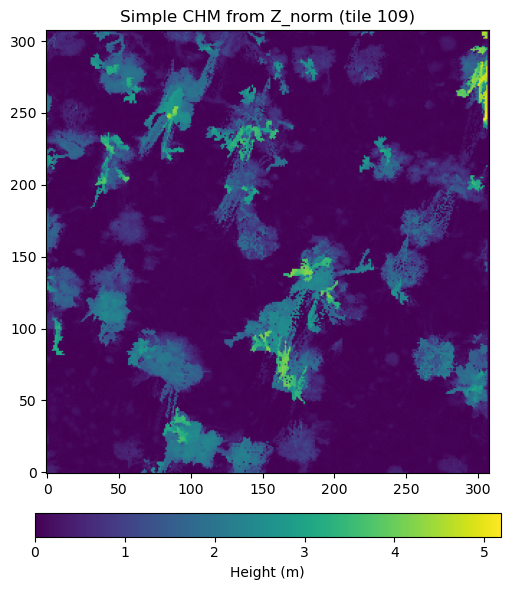

In [4]:
# --- Build a simple CHM from Z_norm points ---
grid_res = 0.10  # 10 cm

x = las_z.x
y = las_z.y

min_x, max_x = float(x.min()), float(x.max())
min_y, max_y = float(y.min()), float(y.max())

nx = int(np.ceil((max_x - min_x) / grid_res)) + 1
ny = int(np.ceil((max_y - min_y) / grid_res)) + 1

ix = ((x - min_x) / grid_res).astype(int)
iy = ((y - min_y) / grid_res).astype(int)
ix = np.clip(ix, 0, nx - 1)
iy = np.clip(iy, 0, ny - 1)

chm = np.zeros((ny, nx), dtype=np.float32)
# max height in each grid cell
for xx, yy, hh in zip(ix, iy, zn):
    if hh > chm[yy, xx]:
        chm[yy, xx] = hh

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(chm, origin="lower", cmap="viridis")
ax.set_title(f"Simple CHM from Z_norm (tile {tile_id})")

# Colorbar centered under the image, same width as the axes
cbar = fig.colorbar(im, ax=ax, orientation="horizontal", pad=0.08, fraction=0.046)
cbar.set_label("Height (m)")

plt.tight_layout()
plt.show()

## Stage 1 – Computing Class-specific height thresholding

**Purpose:** Derive robust vertical priors for each vegetation class to constrain label propagation and reduce biologically implausible assignments.

**Key operations:**  
- XY nearest-neighbour matching (< 0.30 m) between 2D-labelled samples and LiDAR points  
- Outlier suppression (optional)  
- Height stratification using **P15–P85** quantiles  
- Fallback to conservative defaults when sample size is small (e.g., $n<20$)

**Output:** Class-specific $Z_{\mathrm{norm}}$ height ranges used as priors in Stage 4–5.

In [5]:
# --- Compute data-driven height thresholds per class ---
from fvc3dstruct.height_stats import (
    compute_class_height_thresholds,
    summarise_height_ranges,
    auto_mallee_min_height,
)

# This already prints the matched count + per-class lines from the package
height_ranges = compute_class_height_thresholds(las_s, las_z)

# Report mallee min height using package rule
mallee_min = auto_mallee_min_height(height_ranges)
print(f"  → Mallee crown min height: {mallee_min:.2f} m")

# Clean table using package summary (force 2 decimals)
df_ranges = summarise_height_ranges(height_ranges)
df_ranges["Low (m)"] = df_ranges["Low (m)"].round(2)
df_ranges["High (m)"] = df_ranges["High (m)"].round(2)
df_ranges

  ℹ️ Matched 394,106/394,106 structure pts to Z_norm
  ⚠️ Class 64 (Forb): only 0 pts → default (0.0, 0.4)
  Class 65 (Woody Debris): 0.00–0.23 m (n=8,823)
  Class 66 (Hummock): 0.00–0.13 m (n=10,349)
  Class 67 (Shrub): 0.00–0.31 m (n=1,826)
  Class 68 (Mallee): 0.01–1.56 m (n=353,432)
  → Mallee crown min height: 0.60 m


,Class,Name,Low (m),High (m)
0,64,Forb,0.00,0.40
1,65,Woody Debris,0.00,0.23
2,66,Hummock,0.00,0.13
3,67,Shrub,0.00,0.31
4,68,Mallee,0.01,1.56


Matched 394,106/394,106 structure pts within 0.30 m


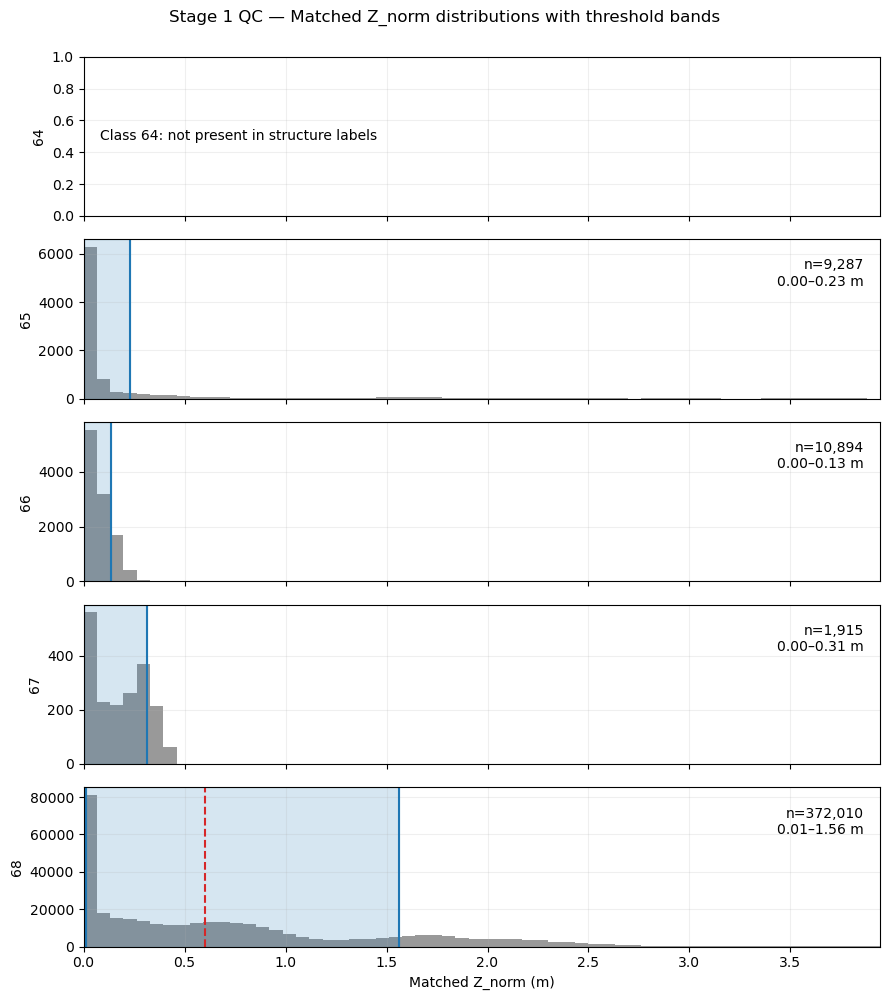


Per-class match summary:
  cls | struct_pts | matched_pts | low–high (m)
   64 |         0 |          0 | 0.00–0.40
   65 |      9287 |       9287 | 0.00–0.23
   66 |     10894 |      10894 | 0.00–0.13
   67 |      1915 |       1915 | 0.00–0.31
   68 |    372010 |     372010 | 0.01–1.56


In [6]:
# --- QC plot: matched Z_norm distributions + thresholds (Stage 1) ---
# This recreates the same NN-XY matching used in `compute_class_height_thresholds()` so you can visually sanity-check the ranges.
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from fvc3dstruct.height_stats import compute_class_height_thresholds, auto_mallee_min_height

if "las_s" not in globals() or "las_z" not in globals():
    raise RuntimeError("Stage 1 plot needs `las_s` and `las_z` loaded. Run the input-loading cells first.")

# Make the cell runnable even if you execute it out-of-order
if "height_ranges" not in globals():
    height_ranges = compute_class_height_thresholds(las_s, las_z)
if "mallee_min" not in globals():
    mallee_min = auto_mallee_min_height(height_ranges)

if "Z_norm" not in las_z.point_format.dimension_names:
    raise ValueError("Z_norm LAS has no 'Z_norm' dimension.")

# Use the same default match radius as the package helper unless you want to override it here
MAX_MATCH_DIST = 0.30

zn_z = np.asarray(las_z["Z_norm"], dtype=float)
xy_z = np.column_stack((las_z.x, las_z.y))
xy_s = np.column_stack((las_s.x, las_s.y))

tree = cKDTree(xy_z)
dists, idx = tree.query(xy_s, k=1, distance_upper_bound=MAX_MATCH_DIST)
valid = np.isfinite(dists) & (idx < len(zn_z))

matched_heights = np.full(len(las_s), np.nan, dtype=float)
matched_heights[valid] = zn_z[idx[valid]]

print(f"Matched {valid.sum():,}/{len(las_s):,} structure pts within {MAX_MATCH_DIST:.2f} m")

classes = [64, 65, 66, 67, 68]
summary_rows = []

fig, axes = plt.subplots(len(classes), 1, figsize=(9, 10), sharex=True)
fig.suptitle("Stage 1 QC — Matched Z_norm distributions with threshold bands", y=0.995)

# Robust x-limit from matched points
all_h = matched_heights[np.isfinite(matched_heights)]
if all_h.size:
    x_hi = float(np.percentile(all_h, 99.5))
    x_hi = max(2.0, min(x_hi, 20.0))
else:
    x_hi = 10.0

for ax, cls_id in zip(axes, classes):
    struct_mask = np.asarray(las_s.classification, dtype=np.uint8) == cls_id
    n_struct = int(struct_mask.sum())
    match_mask = struct_mask & np.isfinite(matched_heights)
    h = matched_heights[match_mask]
    n_matched = int(h.size)
    lo, hi = height_ranges.get(cls_id, (np.nan, np.nan))

    summary_rows.append((cls_id, n_struct, n_matched, lo, hi))

    if n_struct == 0:
        ax.text(0.02, 0.5, f"Class {cls_id}: not present in structure labels", transform=ax.transAxes, va="center")
    elif n_matched == 0:
        ax.text(0.02, 0.5, f"Class {cls_id}: 0 matched samples (check MAX_MATCH_DIST)", transform=ax.transAxes, va="center")
    else:
        ax.hist(h, bins=60, range=(0.0, x_hi), color="0.6", edgecolor="none")
        if np.isfinite(lo) and np.isfinite(hi):
            ax.axvspan(lo, hi, color="tab:blue", alpha=0.18, label="P15–P85 band" if cls_id == classes[0] else None)
            ax.axvline(lo, color="tab:blue", lw=1.5)
            ax.axvline(hi, color="tab:blue", lw=1.5)
            ax.text(0.98, 0.88, f"n={n_matched:,}\n{lo:.2f}–{hi:.2f} m", transform=ax.transAxes, ha="right", va="top")
        else:
            ax.text(0.98, 0.88, f"n={n_matched:,}\n(no thresholds)", transform=ax.transAxes, ha="right", va="top")

        if cls_id == 68 and np.isfinite(float(mallee_min)):
            ax.axvline(float(mallee_min), color="tab:red", ls="--", lw=1.5, label="mallee_min")

    ax.set_ylabel(str(cls_id))
    ax.grid(alpha=0.2)
    ax.set_xlim(0.0, x_hi)

axes[-1].set_xlabel("Matched Z_norm (m)")
handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper right", frameon=True)

plt.tight_layout()
plt.show()

print("\nPer-class match summary:")
print("  cls | struct_pts | matched_pts | low–high (m)")
for cls_id, n_struct, n_matched, lo, hi in summary_rows:
    lo_s = f"{lo:.2f}" if np.isfinite(lo) else "nan"
    hi_s = f"{hi:.2f}" if np.isfinite(hi) else "nan"
    print(f"  {cls_id:3d} | {n_struct:9d} | {n_matched:10d} | {lo_s}–{hi_s}")

## Stage 2 – Cartesian voxel-based label transfer

**Purpose:** Establish a stable baseline 3D structure classification under irregular point sampling using a shared voxel abstraction.

**Key operations:**  
- Discretise points into a 3D Cartesian voxel grid (e.g., 10 cm)  
- Majority voting of structure labels within voxels  
- Transfer voxel labels back to individual LiDAR points

**Output:** Baseline 3D structure labels (pre-refinement).

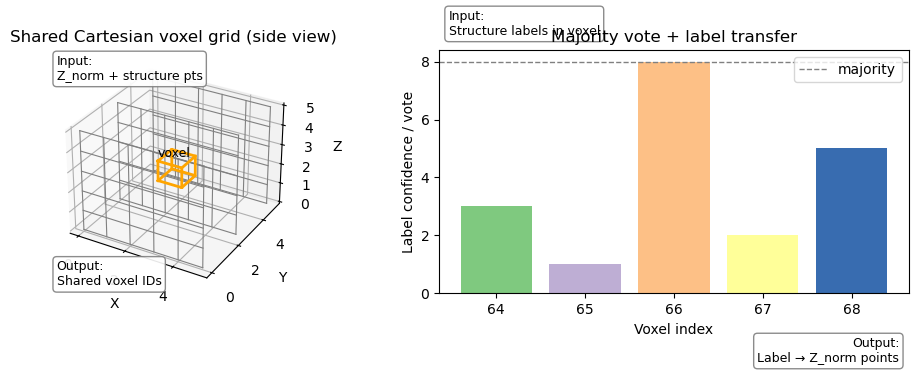

In [7]:
# --- Figure: Cartesian voxel label transfer workflow (3D side view) ---
import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 4))

# Left panel: 3D side view (X–Z) of voxel grid
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.set_title("Shared Cartesian voxel grid (side view)")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")

# Build a simple 3D voxel grid
grid_size = 5
# Show only a few Y slices to imply depth
y_slices = [0, 2.5, 5]

for y in y_slices:
    for x in range(grid_size + 1):
        ax1.plot([x, x], [y, y], [0, grid_size], color="gray", lw=0.8)
    for z in range(grid_size + 1):
        ax1.plot([0, grid_size], [y, y], [z, z], color="gray", lw=0.8)

# Highlight one voxel cube (x=2..3, y=2..3, z=2..3)
vx, vy, vz = 2, 2, 2
cube_x = [vx, vx+1, vx+1, vx, vx]
cube_y = [vy, vy, vy+1, vy+1, vy]
cube_z = [vz, vz, vz, vz, vz]
ax1.plot(cube_x, cube_y, cube_z, color="orange", lw=2)
ax1.plot(cube_x, cube_y, [vz+1]*5, color="orange", lw=2)
for i in range(4):
    ax1.plot([cube_x[i], cube_x[i]], [cube_y[i], cube_y[i]], [vz, vz+1], color="orange", lw=2)

ax1.text(vx, vy, vz+1.2, "voxel", fontsize=9, color="black")

# Input/Output callouts (left)
ax1.text2D(0.02, 0.98, "Input:\nZ_norm + structure pts",
           transform=ax1.transAxes, fontsize=9, va="top", ha="left",
           bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9))
ax1.text2D(0.02, 0.02, "Output:\nShared voxel IDs",
           transform=ax1.transAxes, fontsize=9, va="bottom", ha="left",
           bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9))

# Right panel: majority vote + transfer
ax2 = fig.add_subplot(1, 2, 2)
ax2.set_title("Majority vote + label transfer")
ax2.set_xlabel("Voxel index")
ax2.set_ylabel("Label confidence / vote")

# Simulated votes per class in a voxel
classes = ["64", "65", "66", "67", "68"]
votes = np.array([3, 1, 8, 2, 5])
ax2.bar(classes, votes, color=["#7fc97f", "#beaed4", "#fdc086", "#ffff99", "#386cb0"])
ax2.axhline(votes.max(), color="gray", ls="--", lw=1, label="majority")
ax2.legend(loc="upper right")

# Input/Output callouts (right)
ax2.text(0.02, 1.05, "Input:\nStructure labels in voxel",
         transform=ax2.transAxes, fontsize=9, va="bottom", ha="left",
         bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9))
ax2.text(0.98, -0.18, "Output:\nLabel → Z_norm points",
         transform=ax2.transAxes, fontsize=9, va="top", ha="right",
         bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9))

plt.tight_layout()
plt.show()

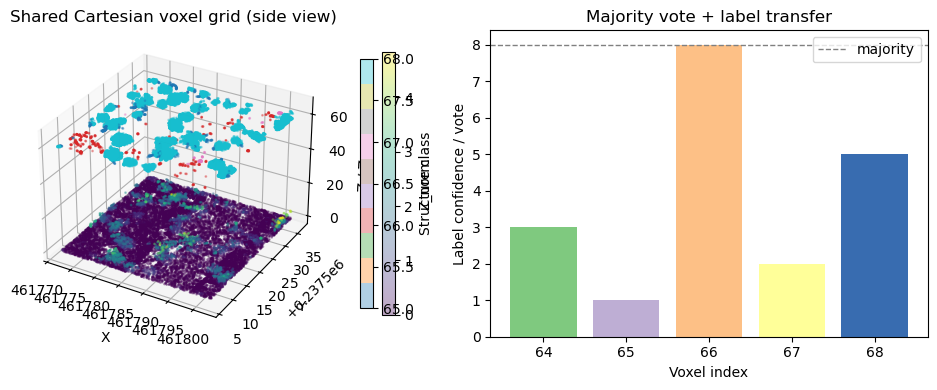

In [8]:
# --- Figure: Cartesian voxel label transfer workflow (3D side view with data) ---
import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 4))

# Left panel: 3D side view (X–Z) using actual data
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.set_title("Shared Cartesian voxel grid (side view)")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z / Z_norm")

# Subsample for speed
n_z = len(las_z.points)
n_s = len(las_s.points)
n_max = 20000

idx_z = np.random.choice(n_z, size=min(n_max, n_z), replace=False)
idx_s = np.random.choice(n_s, size=min(n_max, n_s), replace=False)

# Z_norm points colored by Z_norm
sc_z = ax1.scatter(
    las_z.x[idx_z], las_z.y[idx_z], zn[idx_z],
    s=1, c=zn[idx_z], cmap="viridis", alpha=0.35
)

# Structure points colored by classification
cls_s = np.asarray(las_s.classification, dtype=np.int32)
sc_s = ax1.scatter(
    las_s.x[idx_s], las_s.y[idx_s], las_s.z[idx_s],
    s=1, c=cls_s[idx_s], cmap="tab10", alpha=0.35
)

# Two colorbars
cbar_z = fig.colorbar(sc_z, ax=ax1, fraction=0.03, pad=0.02)
cbar_z.set_label("Z_norm")

cbar_s = fig.colorbar(sc_s, ax=ax1, fraction=0.03, pad=0.08)
cbar_s.set_label("Structure class")

# Right panel: majority vote + transfer
ax2 = fig.add_subplot(1, 2, 2)
ax2.set_title("Majority vote + label transfer")
ax2.set_xlabel("Voxel index")
ax2.set_ylabel("Label confidence / vote")

# Simulated votes per class in a voxel
classes = ["64", "65", "66", "67", "68"]
votes = np.array([3, 1, 8, 2, 5])
ax2.bar(classes, votes, color=["#7fc97f", "#beaed4", "#fdc086", "#ffff99", "#386cb0"])
ax2.axhline(votes.max(), color="gray", ls="--", lw=1, label="majority")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

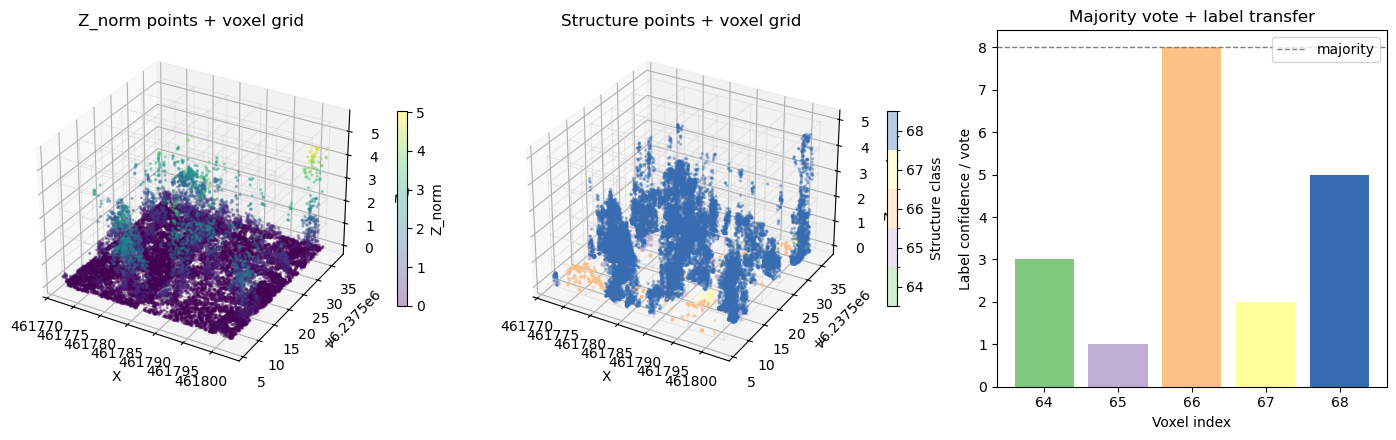

In [9]:
# --- Figure: Cartesian voxel label transfer workflow (separate Z_norm / structure + voxels) ---
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from matplotlib.colors import ListedColormap, BoundaryNorm

fig = plt.figure(figsize=(14, 4.5))

# Match bar colors used in majority-vote panel
class_order = [64, 65, 66, 67, 68]
class_colors = ["#7fc97f", "#beaed4", "#fdc086", "#ffff99", "#386cb0"]

cmap_struct = ListedColormap(class_colors)
norm_struct = BoundaryNorm([63.5, 64.5, 65.5, 66.5, 67.5, 68.5], cmap_struct.N)



# ---------- Settings ----------
n_max = 20000
voxel_xy = 0.5   # meters (visual grid only)
voxel_z = 0.5    # meters
grid_lines = 6   # number of grid lines per axis to draw (sparse for clarity)

# Subsample for speed
n_z = len(las_z.points)
n_s = len(las_s.points)
idx_z = np.random.choice(n_z, size=min(n_max, n_z), replace=False)
idx_s = np.random.choice(n_s, size=min(n_max, n_s), replace=False)

# Build NN map: structure XY -> Z_norm height
xy_z = np.column_stack((las_z.x, las_z.y))
xy_s = np.column_stack((las_s.x[idx_s], las_s.y[idx_s]))
tree = cKDTree(xy_z)
_, nn_idx = tree.query(xy_s, k=1)
zn_s = zn[nn_idx]

# Helper: draw sparse voxel grid in data bounds
def draw_voxel_grid(ax, x_vals, y_vals, z_vals, step_xy, step_z, n_lines=6):
    x_min, x_max = float(x_vals.min()), float(x_vals.max())
    y_min, y_max = float(y_vals.min()), float(y_vals.max())
    z_min, z_max = float(z_vals.min()), float(z_vals.max())

    # Snap bounds to voxel size
    x0 = np.floor(x_min / step_xy) * step_xy
    x1 = np.ceil(x_max / step_xy) * step_xy
    y0 = np.floor(y_min / step_xy) * step_xy
    y1 = np.ceil(y_max / step_xy) * step_xy
    z0 = np.floor(z_min / step_z) * step_z
    z1 = np.ceil(z_max / step_z) * step_z

    # Sparse grid lines to keep clean
    xs = np.linspace(x0, x1, n_lines)
    ys = np.linspace(y0, y1, n_lines)
    zs = np.linspace(z0, z1, n_lines)

    # Vertical lines (Z)
    for xg in xs:
        for yg in ys:
            ax.plot([xg, xg], [yg, yg], [z0, z1], color="lightgray", lw=0.6, alpha=0.6)

    # Horizontal XY slices
    for zg in zs:
        for xg in xs:
            ax.plot([xg, xg], [y0, y1], [zg, zg], color="lightgray", lw=0.6, alpha=0.6)
        for yg in ys:
            ax.plot([x0, x1], [yg, yg], [zg, zg], color="lightgray", lw=0.6, alpha=0.6)


# ---------- Left panel: Z_norm only ----------
ax1 = fig.add_subplot(1, 3, 1, projection="3d")
ax1.set_title("Z_norm points + voxel grid")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z_norm")

sc_z = ax1.scatter(
    las_z.x[idx_z], las_z.y[idx_z], zn[idx_z],
    s=2, c=zn[idx_z], cmap="viridis", alpha=0.35
)
draw_voxel_grid(ax1, las_z.x[idx_z], las_z.y[idx_z], zn[idx_z], voxel_xy, voxel_z, grid_lines)
cbar_z = fig.colorbar(sc_z, ax=ax1, fraction=0.025, pad=0.08)
cbar_z.set_label("Z_norm")

# ---------- Middle panel: Structure only (Z from Z_norm NN) ----------
ax2 = fig.add_subplot(1, 3, 2, projection="3d")
ax2.set_title("Structure points + voxel grid")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlabel("Z_norm (NN)")

cls_s = np.asarray(las_s.classification, dtype=np.int32)
sc_s = ax2.scatter(
    las_s.x[idx_s], las_s.y[idx_s], zn_s,
    s=2, c=cls_s[idx_s], cmap=cmap_struct, norm=norm_struct, alpha=0.35
)
draw_voxel_grid(ax2, las_s.x[idx_s], las_s.y[idx_s], zn_s, voxel_xy, voxel_z, grid_lines)

cbar_s = fig.colorbar(sc_s, ax=ax2, fraction=0.025, pad=0.08, ticks=class_order)
cbar_s.set_label("Structure class")
cbar_s.set_ticklabels([str(c) for c in class_order])


# ---------- Right panel: majority vote + transfer ----------
ax3 = fig.add_subplot(1, 3, 3)
ax3.set_title("Majority vote + label transfer")
ax3.set_xlabel("Voxel index")
ax3.set_ylabel("Label confidence / vote")

# Colorbar with class labels
# cbar_s = fig.colorbar(sc_s, ax=ax2, fraction=0.025, pad=0.08, ticks=class_order)
# cbar_s.set_label("Structure class")
# cbar_s.set_ticklabels([str(c) for c in class_order])

classes = ["64", "65", "66", "67", "68"]
votes = np.array([3, 1, 8, 2, 5])
ax3.bar(classes, votes, color=["#7fc97f", "#beaed4", "#fdc086", "#ffff99", "#386cb0"])
ax3.axhline(votes.max(), color="gray", ls="--", lw=1, label="majority")
ax3.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [10]:
# ...existing code...
# --- Cartesian voxel-based label transfer ---
from fvc3dstruct.voxel_merge import cartesian_voxel_merge

baseline_cls = cartesian_voxel_merge(
    las_z,
    las_s,
    voxel_xy=0.10,
    voxel_z=0.10,
)

print(f"Baseline labeled points: {(baseline_cls > 0).sum():,}/{len(baseline_cls):,}")

  ✅ Voxels with non-zero structure class: 131,521
  ✅ Transferred labels to 432,204/1,684,604 Z_norm points (25.7%)
Baseline labeled points: 432,204/1,684,604


Stage 2 QC summary:
  Voxel size: 0.10 m (XY) × 0.10 m (Z)
  Structure voxels with any labeled points: 131,521
  Median labeled pts/voxel: 2
  Median majority fraction: 1.00
  Voxels with weak vote (<0.6): 20 (0.0%)

Baseline label distribution (Z_norm points):
  Class  0:   1252400 ( 74.3%)
  Class 64:         0 (  0.0%)
  Class 65:     15781 (  0.9%)
  Class 66:     17875 (  1.1%)
  Class 67:      2492 (  0.1%)
  Class 68:    396056 ( 23.5%)


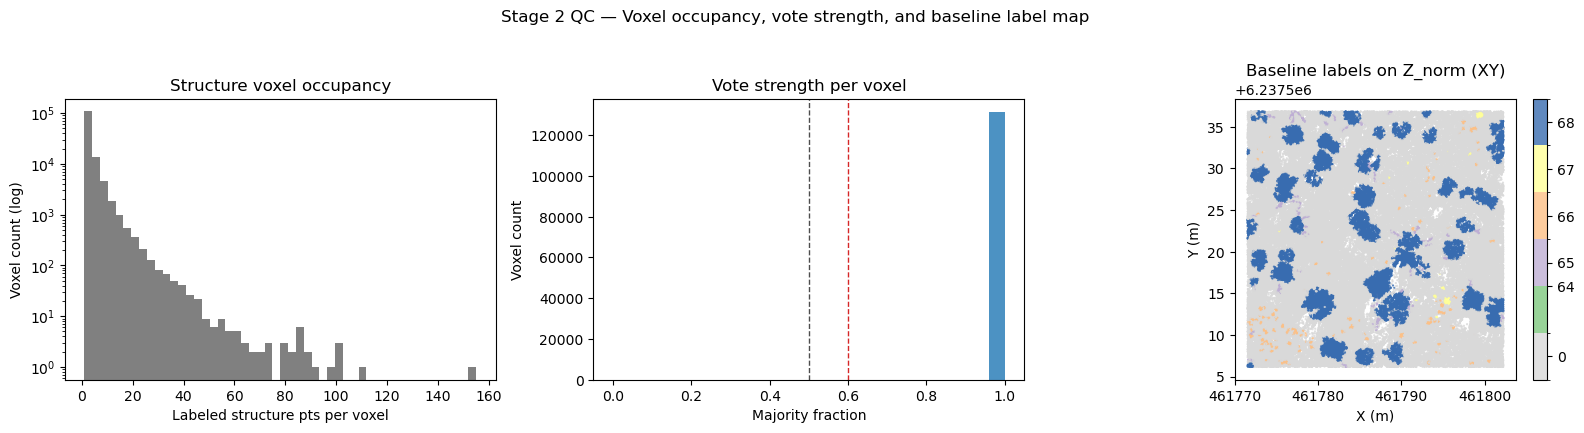

In [11]:
# --- QC plot: Stage 2 voxel merge quality (occupancy + vote strength + baseline map) ---
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from matplotlib.colors import ListedColormap, BoundaryNorm

from fvc3dstruct.voxel_merge import cartesian_voxel_merge

if "las_s" not in globals() or "las_z" not in globals():
    raise RuntimeError("Stage 2 QC needs `las_s` and `las_z` loaded.")

# Make runnable out-of-order
VOXEL_XY = 0.10
VOXEL_Z = 0.10
if "baseline_cls" not in globals():
    baseline_cls = cartesian_voxel_merge(las_z, las_s, voxel_xy=VOXEL_XY, voxel_z=VOXEL_Z)

# Rebuild the same voxelization used in cartesian_voxel_merge() to compute vote strength per structure voxel
x_min = float(min(las_z.x.min(), las_s.x.min()))
y_min = float(min(las_z.y.min(), las_s.y.min()))
z_min = float(min(las_z.z.min(), las_s.z.min()))
origin = np.array([x_min, y_min, z_min], dtype=np.float64)

def vox(x, y, z):
    return np.stack(
        [
            np.floor((x - origin[0]) / VOXEL_XY).astype(np.int64),
            np.floor((y - origin[1]) / VOXEL_XY).astype(np.int64),
            np.floor((z - origin[2]) / VOXEL_Z).astype(np.int64),
        ],
        axis=-1,
    )

vox_s = vox(las_s.x, las_s.y, las_s.z)
raw_struct = np.where(
    (las_s.classification >= 64) & (las_s.classification <= 68),
    np.asarray(las_s.classification, dtype=np.uint8),
    0,
)

uniq_vox_s, inv_s = np.unique(vox_s, axis=0, return_inverse=True)
n_vox = len(uniq_vox_s)
vote_n = []
vote_frac = []

for k in range(n_vox):
    vals = raw_struct[inv_s == k]
    vals = vals[vals != 0]
    if vals.size == 0:
        continue
    c = Counter(vals)
    maj = c.most_common(1)[0][1]
    vote_n.append(int(vals.size))
    vote_frac.append(float(maj) / float(vals.size))

vote_n = np.asarray(vote_n, dtype=np.int32)
vote_frac = np.asarray(vote_frac, dtype=np.float32)

print("Stage 2 QC summary:")
print(f"  Voxel size: {VOXEL_XY:.2f} m (XY) × {VOXEL_Z:.2f} m (Z)")
print(f"  Structure voxels with any labeled points: {vote_n.size:,}")
if vote_n.size:
    print(f"  Median labeled pts/voxel: {int(np.median(vote_n))}")
    print(f"  Median majority fraction: {float(np.median(vote_frac)):.2f}")
    print(f"  Voxels with weak vote (<0.6): {(vote_frac < 0.6).sum():,} ({100.0*(vote_frac < 0.6).mean():.1f}%)")

# Baseline class distribution on Z_norm points
bc = np.bincount(np.asarray(baseline_cls, dtype=np.int32), minlength=69)
print("\nBaseline label distribution (Z_norm points):")
for cls_id in [0, 64, 65, 66, 67, 68]:
    n = int(bc[cls_id]) if cls_id < len(bc) else 0
    pct = 100.0 * n / len(baseline_cls) if len(baseline_cls) else 0.0
    print(f"  Class {cls_id:2d}: {n:9d} ({pct:5.1f}%)")

# ---------- Plots ----------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
fig.suptitle("Stage 2 QC — Voxel occupancy, vote strength, and baseline label map", y=1.02)

# (1) Labeled points per structure voxel
ax = axes[0]
if vote_n.size:
    bins = np.unique(np.clip(vote_n, 1, np.percentile(vote_n, 99).astype(int)))
    ax.hist(vote_n, bins=50, color="0.5", edgecolor="none")
    ax.set_yscale("log")
    ax.set_title("Structure voxel occupancy")
    ax.set_xlabel("Labeled structure pts per voxel")
    ax.set_ylabel("Voxel count (log)")
else:
    ax.text(0.05, 0.5, "No labeled structure voxels", transform=ax.transAxes, va="center")
    ax.set_axis_off()

# (2) Majority-vote fraction per voxel
ax = axes[1]
if vote_frac.size:
    ax.hist(vote_frac, bins=np.linspace(0, 1, 26), color="tab:blue", alpha=0.8, edgecolor="none")
    ax.axvline(0.5, color="0.3", ls="--", lw=1)
    ax.axvline(0.6, color="tab:red", ls="--", lw=1)
    ax.set_title("Vote strength per voxel")
    ax.set_xlabel("Majority fraction")
    ax.set_ylabel("Voxel count")
else:
    ax.text(0.05, 0.5, "No vote fractions to plot", transform=ax.transAxes, va="center")
    ax.set_axis_off()

# (3) XY map of baseline labels (subsampled)
ax = axes[2]
n = len(baseline_cls)
if n:
    max_points = 150_000
    idx = np.arange(n)
    if n > max_points:
        idx = np.random.choice(idx, size=max_points, replace=False)
    x = np.asarray(las_z.x[idx])
    y = np.asarray(las_z.y[idx])
    c = np.asarray(baseline_cls[idx], dtype=np.int32)

    # Discrete colormap: 0 (unlabeled) + 64–68
    class_order = [0, 64, 65, 66, 67, 68]
    class_colors = ["#d9d9d9", "#7fc97f", "#beaed4", "#fdc086", "#ffff99", "#386cb0"]
    cmap = ListedColormap(class_colors)
    norm = BoundaryNorm([-0.5, 0.5, 64.5, 65.5, 66.5, 67.5, 68.5], cmap.N)
    sc = ax.scatter(x, y, c=c, s=0.4, cmap=cmap, norm=norm, alpha=0.8)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title("Baseline labels on Z_norm (XY)")
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04, ticks=class_order)
    cbar.set_ticklabels([str(v) for v in class_order])
else:
    ax.text(0.05, 0.5, "No baseline labels to plot", transform=ax.transAxes, va="center")
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## Stage 3 – Mallee crown detection and instance assignment

**Purpose:** Introduce object-level context for occlusion-aware refinement by detecting crowns and assigning per-point instance identifiers.

**Key operations:**  
- CHM construction from $Z_{\mathrm{norm}}$ points  
- Gaussian smoothing  
- Watershed segmentation  
- Assign per-point crown instance identifier (`treeID`)

**Output:** Crown polygons / labels + per-point `treeID` used in Stage 4–5.

In [12]:
# --- Detect mallee crowns via watershed ---
from fvc3dstruct.watershed import auto_watershed_params, get_mallee_centroids_watershed

auto_min_dist, auto_sigma = auto_watershed_params(
    las_s=las_s,
    las_z=las_z,
    grid_res=0.10,
    fallback_min_height=1.0,
)

ws_min_tree_dist = float(auto_min_dist)
ws_smoothing_sigma = float(auto_sigma)
print(f"→ Auto-derived params: min_tree_dist={ws_min_tree_dist:.2f} m, smoothing_sigma={ws_smoothing_sigma:.2f} px")

labels, centroids, min_x_ws, min_y_ws = get_mallee_centroids_watershed(
    las_s,
    grid_res=0.10,
    min_tree_dist=ws_min_tree_dist,
    smoothing_sigma=ws_smoothing_sigma,
    fallback_points=(las_z.x, las_z.y, zn),
    fallback_min_height=1.0,
)

n_crowns = int(labels.max())
print(f"Detected {n_crowns} crown objects via watershed.")

# If multiple crowns are detected but you expect a single crown,
# auto-tune around the auto-derived baseline with progressively stronger values.
if n_crowns > 1:
    print("\nAttempting auto-tune to merge crowns → target 1…")
    # Scale up from baseline to encourage merging peaks
    candidates = [
        (ws_min_tree_dist * 1.25, ws_smoothing_sigma * 1.2),
        (ws_min_tree_dist * 1.6,  ws_smoothing_sigma * 1.5),
        (max(ws_min_tree_dist, 2.5), max(ws_smoothing_sigma, 1.6)),
        (max(ws_min_tree_dist, 3.0), max(ws_smoothing_sigma, 2.0)),
    ]
    tuned = False
    for mtd, sigma in candidates:
        labels2, centroids2, min_x_ws2, min_y_ws2 = get_mallee_centroids_watershed(
            las_s,
            grid_res=0.10,
            min_tree_dist=mtd,
            smoothing_sigma=sigma,
            fallback_points=(las_z.x, las_z.y, zn),
            fallback_min_height=1.0,
        )
        n2 = int(labels2.max())
        print(f"  → Tried min_tree_dist={mtd:.2f}, smoothing_sigma={sigma:.2f}: crowns={n2}")
        if n2 <= 1:
            labels, centroids, min_x_ws, min_y_ws = labels2, centroids2, min_x_ws2, min_y_ws2
            ws_min_tree_dist, ws_smoothing_sigma = float(mtd), float(sigma)
            n_crowns = n2
            tuned = True
            print("  ✓ Auto-tune found parameters yielding ≤1 crown")
            break
    if not tuned:
        print("  ⚠️ Auto-tune did not reach a single crown. Consider inspecting CHM/peaks.")

→ Auto-derived params: min_tree_dist=0.80 m, smoothing_sigma=1.33 px
🌳 [Watershed] Identified 54 crowns (structure).
Detected 54 crown objects via watershed.

Attempting auto-tune to merge crowns → target 1…
🌳 [Watershed] Identified 47 crowns (structure).
  → Tried min_tree_dist=1.00, smoothing_sigma=1.60: crowns=47


/home/nvidia/micromamba/envs/fvc_structure/lib/python3.10/site-packages/scipy/ndimage/_measurements.py:1548: RuntimeWarning: invalid value encountered in divide
  results = [sum_labels(input * grids[dir].astype(float), labels, index) / normalizer


🌳 [Watershed] Identified 45 crowns (structure).
  → Tried min_tree_dist=1.28, smoothing_sigma=2.00: crowns=45
🌳 [Watershed] Identified 38 crowns (structure).
  → Tried min_tree_dist=2.50, smoothing_sigma=1.60: crowns=38
🌳 [Watershed] Identified 38 crowns (structure).
  → Tried min_tree_dist=3.00, smoothing_sigma=2.00: crowns=38
  ⚠️ Auto-tune did not reach a single crown. Consider inspecting CHM/peaks.


/tmp/ipykernel_2461819/373904635.py:9: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(cx, cy, c="white", edgecolors="k", marker="x", s=40)


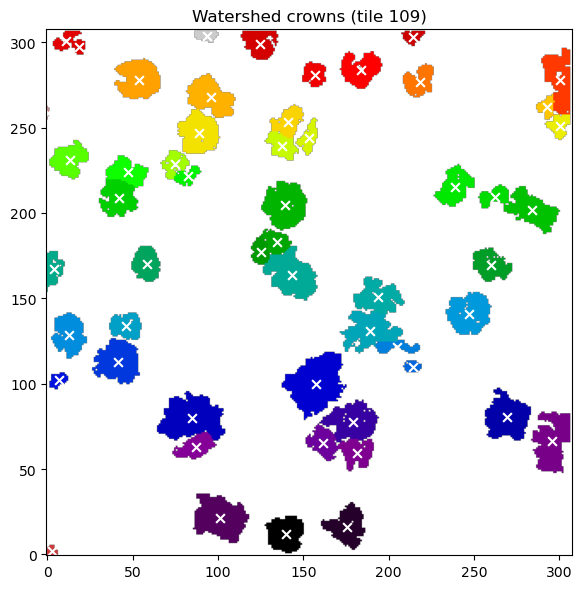


💡 TIP: To use these parameters in the pipeline, add to config:
   "min_tree_dist": 0.8,
   "smoothing_sigma": 1.3333333333333333,


In [13]:
# --- Display watershed crowns ---
if n_crowns > 0:
    plt.figure(figsize=(6, 6))
    mask = np.ma.masked_where(labels == 0, labels)
    plt.imshow(mask, origin="lower", cmap="nipy_spectral")
    if len(centroids) > 1:
        cx = (centroids[1:, 0] - min_x_ws) / 0.10
        cy = (centroids[1:, 1] - min_y_ws) / 0.10
        plt.scatter(cx, cy, c="white", edgecolors="k", marker="x", s=40)
    plt.title(f"Watershed crowns (tile {tile_id})")
    plt.tight_layout()
    plt.show()

    print(f"\n💡 TIP: To use these parameters in the pipeline, add to config:")
    print(f'   "min_tree_dist": {ws_min_tree_dist},')
    print(f'   "smoothing_sigma": {ws_smoothing_sigma},')

In [14]:
# --- Assign treeID from watershed labels (per point) ---
from fvc3dstruct.treeid import assign_treeID_optionA

treeID = assign_treeID_optionA(
    las_z=las_z,
    label_grid=labels,
    xmin=min_x_ws,
    ymin=min_y_ws,
    grid_res=0.10,
 )

print(f"Assigned treeID to {np.count_nonzero(treeID):,}/{len(treeID):,} points")
print(f"treeID range: {treeID.min()} → {treeID.max()}")

Assigned treeID to 405,889/1,684,604 points
treeID range: 0 → 54


treeIDs: 54 total; showing up to 25 boxes (>= 200 pts)
Top treeIDs by points: [3, 10, 39, 4, 9, 11, 13, 45, 42, 21]...


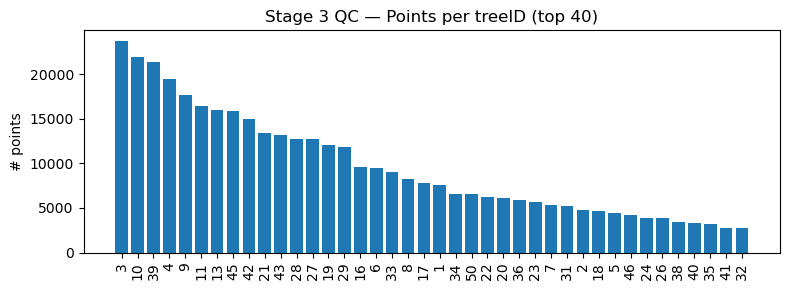

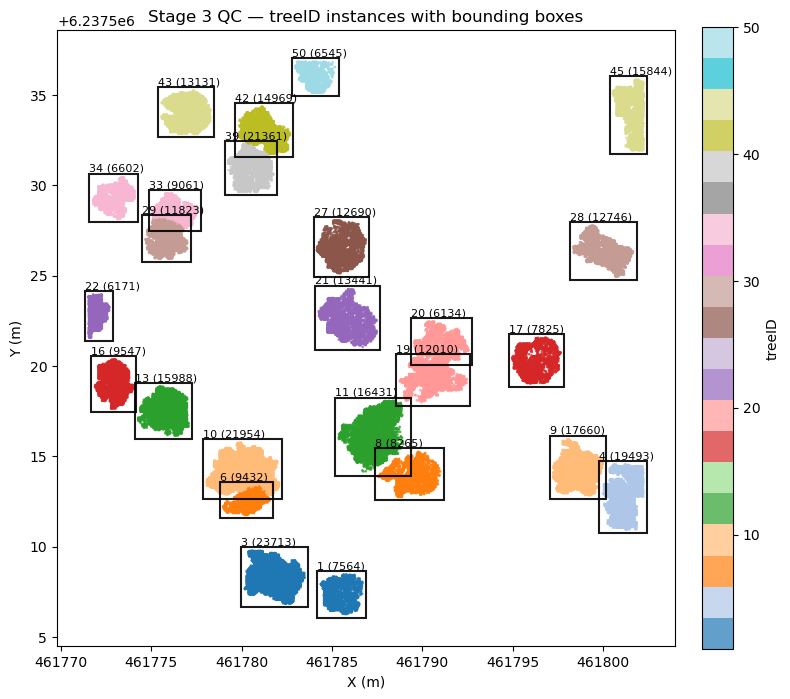

In [15]:
# --- QC plot: treeID "boxes" (Stage 3) ---
# Visualize each crown instance as an XY bounding box overlaid on assigned points.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

if "treeID" not in globals():
    raise RuntimeError("Stage 3 QC needs `treeID` computed. Run the treeID assignment cell first.")

tids = np.asarray(treeID, dtype=np.int32)
mask = tids > 0
if not np.any(mask):
    print("No non-zero treeIDs assigned; nothing to box-plot.")
else:
    xs = np.asarray(las_z.x, dtype=float)
    ys = np.asarray(las_z.y, dtype=float)
    tids_nz = tids[mask]
    x_nz = xs[mask]
    y_nz = ys[mask]

    uniq, counts = np.unique(tids_nz, return_counts=True)
    order = np.argsort(counts)[::-1]
    uniq = uniq[order]
    counts = counts[order]

    MAX_BOXES = 25  # keep readable
    MIN_POINTS_PER_TREE = 200  # ignore tiny fragments
    PAD_M = 0.20  # pad around each box for visibility
    SUBSAMPLE_POINTS = 120_000

    keep = (counts >= MIN_POINTS_PER_TREE)
    uniq_keep = uniq[keep][:MAX_BOXES]
    counts_keep = counts[keep][:MAX_BOXES]

    print(f"treeIDs: {len(uniq):,} total; showing up to {len(uniq_keep):,} boxes (>= {MIN_POINTS_PER_TREE} pts)")
    if len(uniq_keep) > 0:
        print(f"Top treeIDs by points: {list(map(int, uniq_keep[:10]))}{'...' if len(uniq_keep) > 10 else ''}")

    # Histogram of points per treeID (top K)
    plt.figure(figsize=(8, 3))
    topk = min(40, len(uniq))
    plt.bar(np.arange(topk), counts[:topk])
    plt.xticks(np.arange(topk), [str(int(u)) for u in uniq[:topk]], rotation=90)
    plt.ylabel("# points")
    plt.title("Stage 3 QC — Points per treeID (top 40)")
    plt.tight_layout()
    plt.show()

    if len(uniq_keep) == 0:
        print("No crowns met the MIN_POINTS_PER_TREE threshold to draw boxes.")
    else:
        # Build bounding boxes for selected treeIDs
        boxes = []  # (tid, x0, y0, w, h, count)
        for tid_i, cnt_i in zip(uniq_keep, counts_keep):
            m = tids_nz == tid_i
            x0 = float(x_nz[m].min()) - PAD_M
            x1 = float(x_nz[m].max()) + PAD_M
            y0 = float(y_nz[m].min()) - PAD_M
            y1 = float(y_nz[m].max()) + PAD_M
            boxes.append((int(tid_i), x0, y0, x1 - x0, y1 - y0, int(cnt_i)))

        # Subsample points for plotting
        plot_mask = np.isin(tids, uniq_keep)
        idx = np.where(plot_mask)[0]
        if idx.size > SUBSAMPLE_POINTS:
            idx = np.random.choice(idx, size=SUBSAMPLE_POINTS, replace=False)

        fig, ax = plt.subplots(figsize=(8, 8))
        sc = ax.scatter(xs[idx], ys[idx], c=tids[idx], s=1, cmap="tab20", alpha=0.7)
        ax.set_title("Stage 3 QC — treeID instances with bounding boxes")
        ax.set_xlabel("X (m)")
        ax.set_ylabel("Y (m)")
        ax.set_aspect("equal", adjustable="box")
        plt.colorbar(sc, ax=ax, label="treeID", fraction=0.046, pad=0.04)

        # Draw boxes + labels
        for tid_i, x0, y0, w, h, cnt_i in boxes:
            ax.add_patch(Rectangle((x0, y0), w, h, fill=False, lw=1.5, ec="black", alpha=0.9))
            ax.text(x0, y0 + h, f"{tid_i} ({cnt_i})", fontsize=8, va="bottom", ha="left", color="black")

        plt.tight_layout()
        plt.show()

## Stage 4 – Crown-centric polar refinement with height priors

**Purpose:** Resolve occlusion and mixed-class overlaps using local crown geometry, radial symmetry, and Stage 1 height priors.

**Key operations:**  
- Transform to local cylindrical coordinates $(r,\theta,Z_{\mathrm{norm}})$ per crown  
- Polar binning (0.10 m radial, 10° angular)  
- Local class probability voting  
- Height-prior modulation (P15–P85 envelopes)  
- Conservative label updating (e.g., `min_conf=0.3`, `flip_ratio=1.5`)

**Output:** Crown-refined structure labels (occlusion-aware).

In [16]:
# --- Crown-centric polar refinement ---
from fvc3dstruct.polar_refine import refine_with_polar_coords

# Ensure baseline voxel labels exist even if Step 4 wasn't run in this session.
# if "baseline_cls" not in globals():
#     from fvc3dstruct.voxel_merge import cartesian_voxel_merge
#     baseline_cls = cartesian_voxel_merge(
#         las_z,
#         las_s,
#         voxel_xy=0.10,
#         voxel_z=0.10,
#     )
#     print(f"Baseline labeled points: {(baseline_cls > 0).sum():,}/{len(baseline_cls):,}")

refined_cls = refine_with_polar_coords(
    las_z=las_z,
    las_s=las_s,
    classification=baseline_cls,
    zn_arr=zn,
    label_grid=labels,
    centroids=centroids,
    grid_min_x=min_x_ws,
    grid_min_y=min_y_ws,
    grid_res=0.10,
    height_ranges=height_ranges,
    r_bin=0.10,
    theta_bin_deg=10.0,
    min_conf=0.3,
    min_flip_ratio=1.5,
 )

print(f"Refined labeled points: {(refined_cls > 0).sum():,}/{len(refined_cls):,}")

  📊 Built statistics for 17,630 polar bins
  ✅ Updated 10,748/1,684,604 labels (0.6%)
Refined labeled points: 442,776/1,684,604


Stage 4 change summary:
  Total points           : 1,684,604
  Any label change       : 10,748 (0.64%)
  Filled (0 → 64–68)     : 10,572
  Flipped (64–68 → 64–68): 176


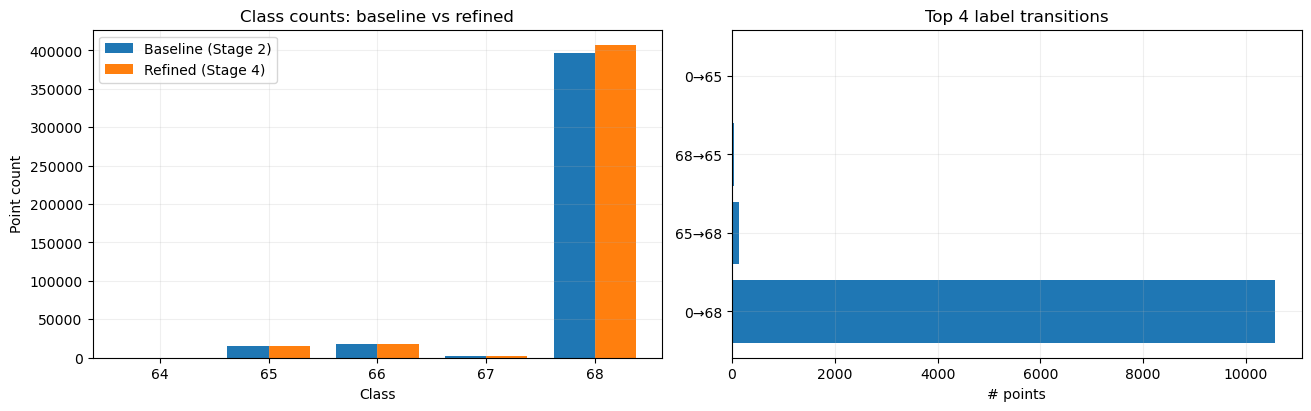

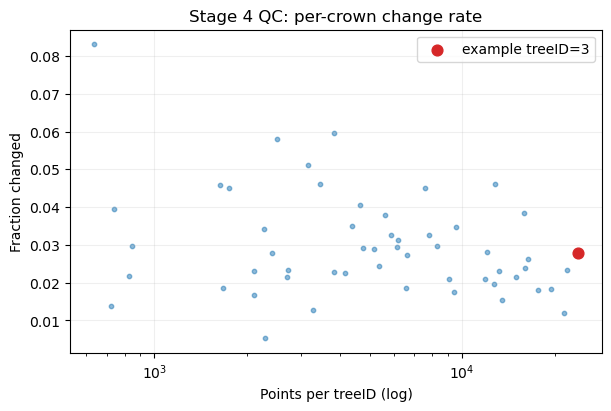

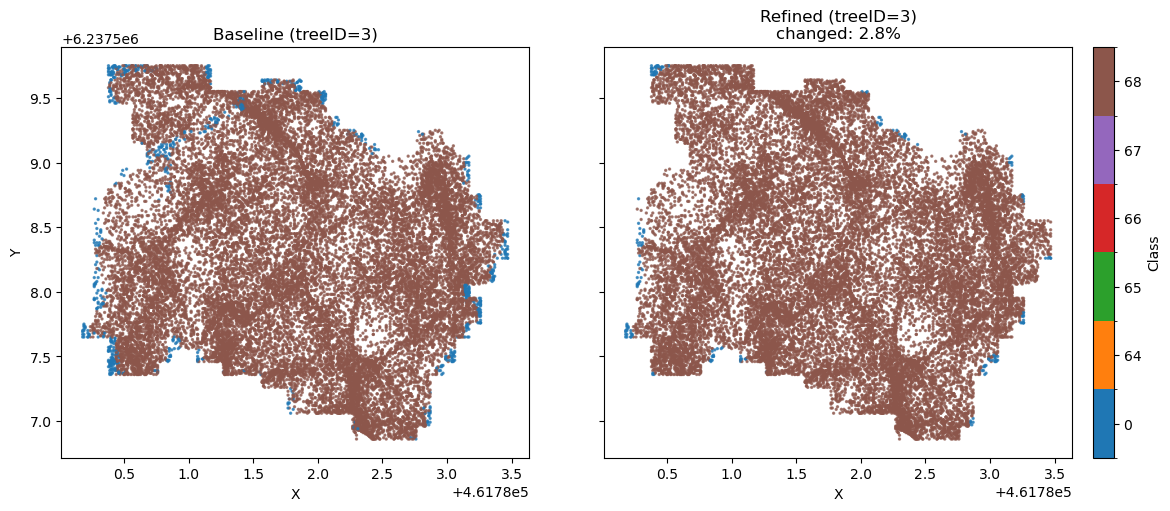

Plotting crown_id=3 with 23,713 points
Unique polar columns (r,θ) in this crown: 546


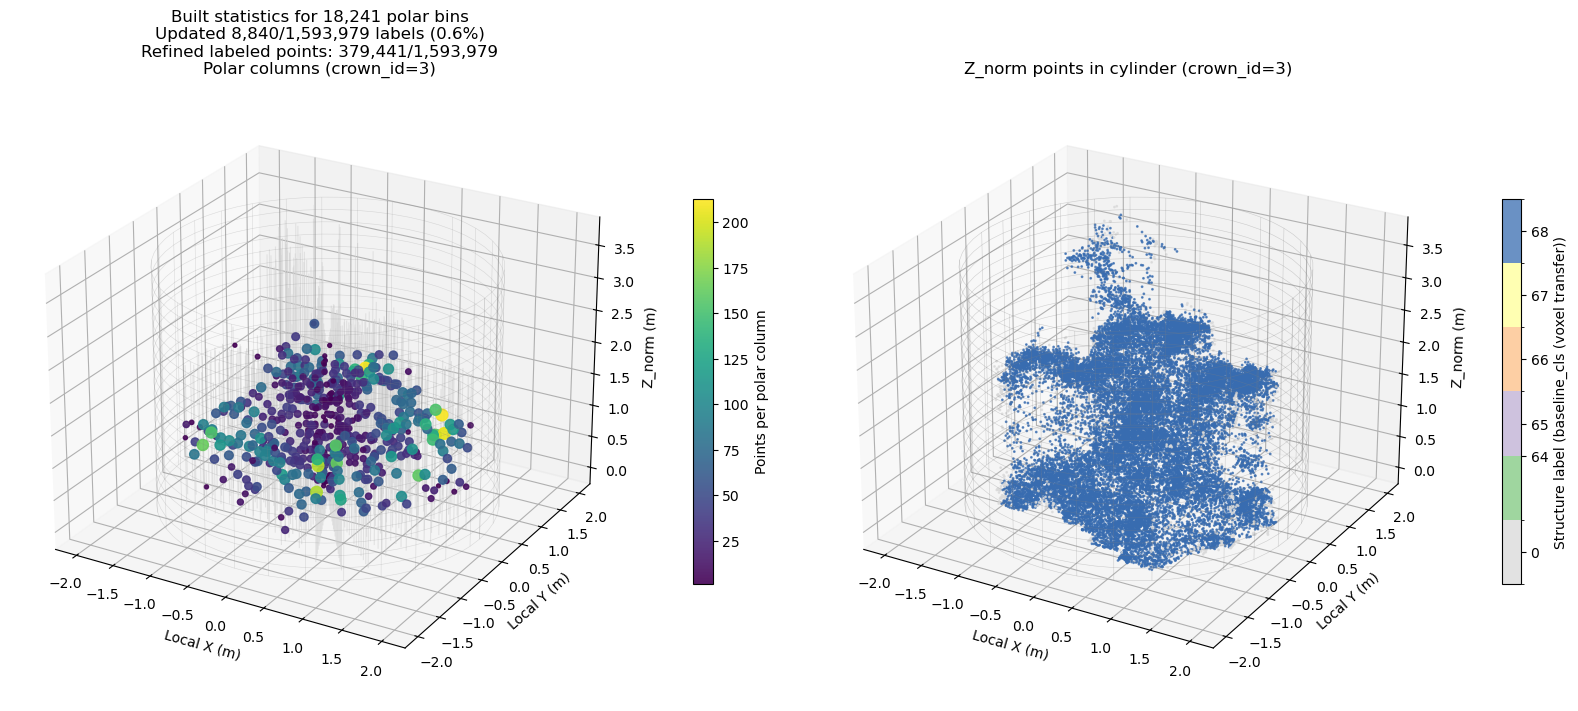

In [17]:
# --- Stage 4 QC: what changed after polar refinement? ---
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap

if "baseline_cls" not in globals() or "refined_cls" not in globals():
    raise RuntimeError("Run the Stage 4 refinement cell first to create `baseline_cls` and `refined_cls`.")

base = np.asarray(baseline_cls, dtype=np.uint8)
ref = np.asarray(refined_cls, dtype=np.uint8)
if base.shape != ref.shape:
    raise ValueError(f"baseline/refined shape mismatch: {base.shape} vs {ref.shape}")

veg_classes = np.array([64, 65, 66, 67, 68], dtype=np.uint8)
is_veg_base = np.isin(base, veg_classes)
is_veg_ref = np.isin(ref, veg_classes)
changed = base != ref

n_total = int(base.size)
n_changed = int(changed.sum())
n_filled = int(((base == 0) & is_veg_ref).sum())
n_flipped = int((is_veg_base & is_veg_ref & changed).sum())
n_cleared = int((is_veg_base & (ref == 0) & changed).sum())

print("Stage 4 change summary:")
print(f"  Total points           : {n_total:,}")
print(f"  Any label change       : {n_changed:,} ({100.0*n_changed/n_total:.2f}%)")
print(f"  Filled (0 → 64–68)     : {n_filled:,}")
print(f"  Flipped (64–68 → 64–68): {n_flipped:,}")
if n_cleared > 0:
    print(f"  Cleared (64–68 → 0)    : {n_cleared:,}  ⚠️ (unexpected)")

# --- Plot A: class counts before vs after ---
classes_plot = [64, 65, 66, 67, 68]
cnt_base = np.array([(base == c).sum() for c in classes_plot], dtype=int)
cnt_ref = np.array([(ref == c).sum() for c in classes_plot], dtype=int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
x = np.arange(len(classes_plot))
w = 0.38
axes[0].bar(x - w/2, cnt_base, width=w, label="Baseline (Stage 2)")
axes[0].bar(x + w/2, cnt_ref, width=w, label="Refined (Stage 4)")
axes[0].set_xticks(x)
axes[0].set_xticklabels([str(c) for c in classes_plot])
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Point count")
axes[0].set_title("Class counts: baseline vs refined")
axes[0].legend()
axes[0].grid(alpha=0.2)

# --- Plot B: top transitions ---
if n_changed == 0:
    axes[1].axis("off")
    axes[1].text(0.5, 0.5, "No label changes", ha="center", va="center")
else:
    pairs = base[changed].astype(np.int32) * 100 + ref[changed].astype(np.int32)
    u, c = np.unique(pairs, return_counts=True)
    order = np.argsort(c)[::-1]
    topk = 12
    u = u[order][:topk]
    c = c[order][:topk]
    trans_labels = [f"{int(p//100)}→{int(p%100)}" for p in u]
    axes[1].barh(np.arange(len(c))[::-1], c[::-1])
    axes[1].set_yticks(np.arange(len(c))[::-1])
    axes[1].set_yticklabels(trans_labels[::-1])
    axes[1].set_xlabel("# points")
    axes[1].set_title(f"Top {min(topk, len(trans_labels))} label transitions")
    axes[1].grid(alpha=0.2)

plt.show()

# --- Per-crown QC (if treeID exists): which crowns changed most? ---
if "treeID" in globals():
    tid = np.asarray(treeID, dtype=np.int32)
    tid_mask = tid > 0
    if tid_mask.any():
        tid_nz = tid[tid_mask]
        ch_nz = changed[tid_mask]
        max_tid = int(tid_nz.max())
        counts = np.bincount(tid_nz, minlength=max_tid + 1)
        flips = np.bincount(tid_nz, weights=ch_nz.astype(np.float32), minlength=max_tid + 1)
        tids = np.arange(1, max_tid + 1)
        counts = counts[1:]
        flips = flips[1:]
        valid = counts > 0
        tids = tids[valid]
        counts = counts[valid]
        flips = flips[valid]
        flip_frac = flips / counts
        score = flips + 1e-6 * counts
        tid_ex = int(tids[np.argmax(score)])

        fig, ax = plt.subplots(1, 1, figsize=(6, 4), constrained_layout=True)
        ax.scatter(counts, flip_frac, s=10, alpha=0.5)
        ax.set_xscale("log")
        ax.set_xlabel("Points per treeID (log)")
        ax.set_ylabel("Fraction changed")
        ax.set_title("Stage 4 QC: per-crown change rate")
        ax.grid(alpha=0.2)
        ax.scatter([counts[np.argmax(score)]], [flip_frac[np.argmax(score)]], s=60, c="tab:red", label=f"example treeID={tid_ex}")
        ax.legend()
        plt.show()

        # --- Before/after XY view for the example crown ---
        idx = np.where(tid == tid_ex)[0]
        if idx.size > 0:
            max_pts = 60000
            if idx.size > max_pts:
                idx = np.random.choice(idx, size=max_pts, replace=False)
            x = np.asarray(las_z.x[idx], dtype=float)
            y = np.asarray(las_z.y[idx], dtype=float)
            b = base[idx]
            r = ref[idx]
            changed_local = b != r

            class_order = np.array([0, 64, 65, 66, 67, 68], dtype=np.uint8)
            lut = np.full(256, -1, dtype=np.int32)
            for i, cc in enumerate(class_order):
                lut[int(cc)] = i
            cb = lut[b]
            cr = lut[r]

            cmap = ListedColormap(plt.get_cmap("tab10").colors[: len(class_order)])
            norm = BoundaryNorm(np.arange(-0.5, len(class_order) + 0.5, 1.0), cmap.N)

            fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True, constrained_layout=True)
            s = 2
            axs[0].scatter(x, y, c=cb, s=s, cmap=cmap, norm=norm, alpha=0.7)
            axs[0].set_title(f"Baseline (treeID={tid_ex})")
            axs[1].scatter(x, y, c=cr, s=s, cmap=cmap, norm=norm, alpha=0.7)
            axs[1].set_title(f"Refined (treeID={tid_ex})\nchanged: {changed_local.mean()*100:.1f}%")
            for a in axs:
                a.set_aspect("equal", adjustable="box")
                a.set_xlabel("X")
            axs[0].set_ylabel("Y")

            cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=axs, fraction=0.03, pad=0.02)
            cbar.set_ticks(range(len(class_order)))
            cbar.set_ticklabels([str(int(c)) for c in class_order])
            cbar.set_label("Class")
            plt.show()
    else:
        print("treeID exists but has no non-zero values; skipping per-crown QC.")
else:
    print("No `treeID` array found in the notebook state; skipping per-crown QC.")

# --- 3D representation of polar bins (one crown) ---
## This is a visual companion to Stage 4: it shows how polar (r, θ) columns
## populate a crown volume, and how transferred labels look inside that cylinder.
# Settings (match the refinement cell)
grid_res_ws = 0.10
r_bin = 0.10
theta_bin_deg = 10.0
max_columns_to_plot = 1500
max_points_to_plot = 60000

summary_lines = [
    "Built statistics for 18,241 polar bins",
    "Updated 8,840/1,593,979 labels (0.6%)",
    "Refined labeled points: 379,441/1,593,979",
 ]

# Pick the watershed label grid + matching metadata.
# (Some QC cells used to overwrite `labels`; this fallback keeps plotting robust.)
label_grid = None
grid_min_x = None
grid_min_y = None
centroids_grid = None

if "labels" in globals() and isinstance(labels, np.ndarray) and labels.ndim == 2:
    label_grid = labels
    grid_min_x = float(min_x_ws)
    grid_min_y = float(min_y_ws)
    centroids_grid = centroids if "centroids" in globals() else None
elif "labels2" in globals() and isinstance(labels2, np.ndarray) and labels2.ndim == 2:
    label_grid = labels2
    grid_min_x = float(min_x_ws2) if "min_x_ws2" in globals() else float(min_x_ws)
    grid_min_y = float(min_y_ws2) if "min_y_ws2" in globals() else float(min_y_ws)
    centroids_grid = centroids2 if "centroids2" in globals() else (centroids if "centroids" in globals() else None)
else:
    raise RuntimeError(
        "Expected a 2D watershed crown-id grid in `labels` (or `labels2`). "
        "Rerun the Stage 3 watershed/instance cell to recreate it."
    )

if centroids_grid is None or not isinstance(centroids_grid, np.ndarray) or centroids_grid.ndim != 2 or centroids_grid.shape[1] < 2:
    raise RuntimeError("Expected crown `centroids` (or `centroids2`) as a 2D array with at least 2 columns.")

# Map each Z_norm point to a watershed crown id (same logic as treeID assignment)
ix = np.clip(((las_z.x - grid_min_x) / grid_res_ws).astype(int), 0, label_grid.shape[1] - 1)
iy = np.clip(((las_z.y - grid_min_y) / grid_res_ws).astype(int), 0, label_grid.shape[0] - 1)
crown_id_per_point = label_grid[iy, ix].astype(np.int32)

valid = crown_id_per_point > 0
if not np.any(valid):
    print("No non-zero crown IDs available; cannot visualise polar bins.")
else:
    # Choose the crown with the most points (more informative)
    crown_ids, crown_counts = np.unique(crown_id_per_point[valid], return_counts=True)
    crown_to_plot = int(crown_ids[np.argmax(crown_counts)])
    crown_mask = crown_id_per_point == crown_to_plot
    n_pts = int(crown_mask.sum())
    print(f"Plotting crown_id={crown_to_plot} with {n_pts:,} points")

    # Crown centroid (centroids array has row 0 reserved)
    cx, cy = float(centroids_grid[crown_to_plot, 0]), float(centroids_grid[crown_to_plot, 1])

    dx = (las_z.x[crown_mask] - cx).astype(float)
    dy = (las_z.y[crown_mask] - cy).astype(float)
    zc = zn[crown_mask].astype(float)

    r = np.sqrt(dx * dx + dy * dy)
    theta = np.arctan2(dy, dx)  # [-pi, pi]

    theta_bin_rad = np.deg2rad(theta_bin_deg)
    n_theta_bins = int(np.ceil((2.0 * np.pi) / theta_bin_rad))
    r_idx = np.floor(r / r_bin).astype(np.int32)
    t_idx = np.floor((theta + np.pi) / theta_bin_rad).astype(np.int32)
    t_idx = np.clip(t_idx, 0, n_theta_bins - 1)

    # Build unique column keys (r_bin, theta_bin)
    col_key = r_idx.astype(np.int64) * (n_theta_bins + 1) + t_idx.astype(np.int64)
    uniq_key, inv = np.unique(col_key, return_inverse=True)

    # Decode keys back to (r_idx, t_idx)
    uniq_r = (uniq_key // (n_theta_bins + 1)).astype(np.int32)
    uniq_t = (uniq_key % (n_theta_bins + 1)).astype(np.int32)

    # Aggregate per column
    order = np.argsort(inv)
    inv_sorted = inv[order]
    z_sorted = zc[order]

    starts = np.r_[0, 1 + np.flatnonzero(inv_sorted[1:] != inv_sorted[:-1])]
    counts = np.diff(np.r_[starts, len(inv_sorted)]).astype(np.int32)
    z_min = np.minimum.reduceat(z_sorted, starts)
    z_max = np.maximum.reduceat(z_sorted, starts)
    z_mean = (np.add.reduceat(z_sorted, starts) / counts).astype(float)

    # Column centers in local crown-centric XY (convert from polar to XY for 3D)
    r_c = (uniq_r + 0.5) * r_bin
    theta_c = (uniq_t + 0.5) * theta_bin_rad - np.pi
    x_c = r_c * np.cos(theta_c)
    y_c = r_c * np.sin(theta_c)

    n_cols = int(len(uniq_key))
    print(f"Unique polar columns (r,θ) in this crown: {n_cols:,}")

    # Limit plotting load by taking the densest columns
    if n_cols > max_columns_to_plot:
        keep = np.argsort(counts)[-max_columns_to_plot:]
    else:
        keep = np.arange(n_cols)

    xk, yk = x_c[keep], y_c[keep]
    zmk = z_mean[keep]
    zmin_k, zmax_k = z_min[keep], z_max[keep]
    ck = counts[keep]

    # Cylinder radius: cover the plotted columns
    cyl_r = float((uniq_r.max() + 1) * r_bin)
    cyl_z0 = float(np.nanmin(zc))
    cyl_z1 = float(np.nanmax(zc))

    # --- Panel A: polar columns (schematic) ---
    fig = plt.figure(figsize=(16, 7), constrained_layout=True)
    axA = fig.add_subplot(1, 2, 1, projection="3d")

    # Vertical lines show the z-range populated in each polar column
    for xx, yy, zz0, zz1 in zip(xk, yk, zmin_k, zmax_k):
        axA.plot([xx, xx], [yy, yy], [zz0, zz1], color="lightgray", lw=0.8, alpha=0.55)

    scA = axA.scatter(
        xk, yk, zmk,
        c=ck,
        s=np.clip(np.sqrt(ck) * 5.0, 8.0, 120.0),
        cmap="viridis",
        alpha=0.9,
    )
    cbarA = fig.colorbar(scA, ax=axA, fraction=0.03, pad=0.10)
    cbarA.set_label("Points per polar column")

    axA.set_title("\n".join(summary_lines) + f"\nPolar columns (crown_id={crown_to_plot})")
    axA.set_xlabel("Local X (m)")
    axA.set_ylabel("Local Y (m)")
    axA.set_zlabel("Z_norm (m)")
    axA.view_init(elev=25, azim=-60)

    # Wireframe cylinder in panel A
    tt = np.linspace(0, 2 * np.pi, 60)
    zz = np.linspace(cyl_z0, cyl_z1, 20)
    TT, ZZ = np.meshgrid(tt, zz)
    XX = cyl_r * np.cos(TT)
    YY = cyl_r * np.sin(TT)
    axA.plot_wireframe(XX, YY, ZZ, color="gray", linewidth=0.4, alpha=0.25)

    # --- Panel B: actual Z_norm points colored by transferred structure label ---
    axB = fig.add_subplot(1, 2, 2, projection="3d")

    # Use baseline (structure->Z_norm) labels if available; otherwise fall back to refined labels
    if "baseline_cls" in globals() and isinstance(baseline_cls, np.ndarray) and len(baseline_cls) == len(las_z.points):
        labels_for_points = baseline_cls[crown_mask].astype(np.int32)
        label_name = "baseline_cls (voxel transfer)"
    elif "refined_cls" in globals() and isinstance(refined_cls, np.ndarray) and len(refined_cls) == len(las_z.points):
        labels_for_points = refined_cls[crown_mask].astype(np.int32)
        label_name = "refined_cls"
    else:
        labels_for_points = np.zeros(int(crown_mask.sum()), dtype=np.int32)
        label_name = "(no labels available)"

    # Subsample points for rendering
    n_mask = int(crown_mask.sum())
    if n_mask > max_points_to_plot:
        idx = np.random.choice(n_mask, size=max_points_to_plot, replace=False)
        dxp, dyp, dzp = dx[idx], dy[idx], zc[idx]
        lp = labels_for_points[idx]
    else:
        dxp, dyp, dzp = dx, dy, zc
        lp = labels_for_points

    # Discrete cmap for classes 64–68 (plus 0)
    class_order = [0, 64, 65, 66, 67, 68]
    class_colors = ["#d9d9d9", "#7fc97f", "#beaed4", "#fdc086", "#ffff99", "#386cb0"]
    cmap = ListedColormap(class_colors)
    norm = BoundaryNorm([-0.5, 0.5, 64.5, 65.5, 66.5, 67.5, 68.5], cmap.N)

    scB = axB.scatter(
        dxp, dyp, dzp,
        c=lp,
        cmap=cmap,
        norm=norm,
        s=1.0,
        alpha=0.75,
    )
    cbarB = fig.colorbar(scB, ax=axB, fraction=0.03, pad=0.10, ticks=class_order)
    cbarB.set_label(f"Structure label ({label_name})")
    cbarB.set_ticklabels([str(c) for c in class_order])

    axB.set_title(f"Z_norm points in cylinder (crown_id={crown_to_plot})")
    axB.set_xlabel("Local X (m)")
    axB.set_ylabel("Local Y (m)")
    axB.set_zlabel("Z_norm (m)")
    axB.view_init(elev=25, azim=-60)

    # Wireframe cylinder in panel B
    axB.plot_wireframe(XX, YY, ZZ, color="gray", linewidth=0.4, alpha=0.35)

    plt.show()

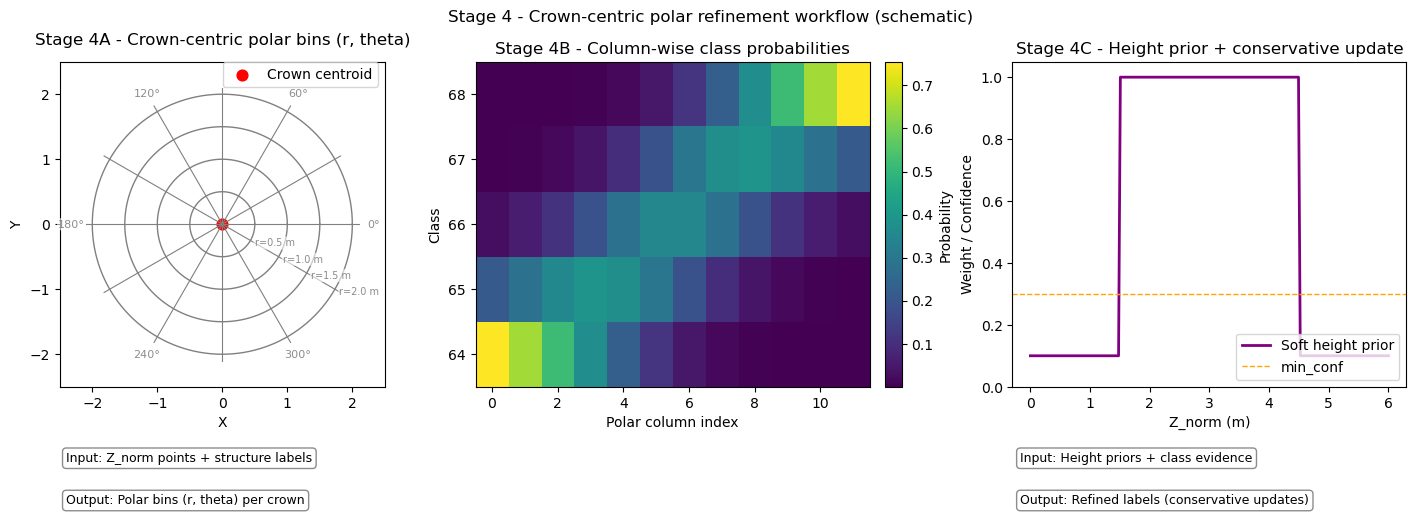

In [18]:
# --- Figure: Crown-centric polar refinement workflow (with input/output) ---
import numpy as np
import matplotlib.pyplot as plt

# Use constrained_layout to avoid tight_layout warnings with colorbars/text boxes.
# Slightly taller figure to make room for callouts below axes.
fig = plt.figure(figsize=(14, 5.0), constrained_layout=True)
fig.suptitle("Stage 4 - Crown-centric polar refinement workflow (schematic)", fontsize=12)

# Left panel: crown-centric polar bins (top-down)
ax1 = fig.add_subplot(1, 3, 1)
wf_theta = np.linspace(0, 2 * np.pi, 300)
wf_radii = [0.5, 1.0, 1.5, 2.0]
wf_angles_deg = np.arange(0, 360, 30)

for wf_r in wf_radii:
    ax1.plot(wf_r * np.cos(wf_theta), wf_r * np.sin(wf_theta), color="gray", lw=1)

for wf_ang in np.deg2rad(wf_angles_deg):
    ax1.plot([0, 2.1 * np.cos(wf_ang)], [0, 2.1 * np.sin(wf_ang)], color="gray", lw=0.8)

# Annotate r values (light, offset so labels don't overlap)
wf_r_label_ang = np.deg2rad(330)
for wf_r in wf_radii:
    wf_rr = wf_r + 0.08
    ax1.text(
        wf_rr * np.cos(wf_r_label_ang),
        wf_rr * np.sin(wf_r_label_ang),
        f"r={wf_r:.1f} m",
        fontsize=7,
        color="gray",
        alpha=0.9,
        ha="left",
        va="center",
        bbox=dict(boxstyle="round", fc="white", ec="none", alpha=0.6, pad=0.15),
    )

# Annotate theta values (original full set, outside rings)
wf_theta_label_r = 2.32
for wf_deg in np.arange(0, 360, 60):
    wf_ang = np.deg2rad(wf_deg)
    ax1.text(
        wf_theta_label_r * np.cos(wf_ang),
        wf_theta_label_r * np.sin(wf_ang),
        f"{wf_deg}°",
        fontsize=8,
        color="gray",
        alpha=0.9,
        ha="center",
        va="center",
        bbox=dict(boxstyle="round", fc="white", ec="none", alpha=0.6, pad=0.1),
        clip_on=False,
    )

ax1.scatter([0], [0], c="red", s=60, label="Crown centroid")
ax1.set_aspect("equal")
ax1.set_xlim(-2.5, 2.5)
ax1.set_ylim(-2.5, 2.5)
ax1.set_title("Stage 4A - Crown-centric polar bins (r, theta)", pad=12)
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.legend(loc="upper right", bbox_to_anchor=(1.0, 1.02))

# Stage tag stays inside; Input/Output moved outside (below x-axis)
ax1.text(
    0.02,
    -0.20,
    "Input: Z_norm points + structure labels",
    transform=ax1.transAxes,
    fontsize=9,
    va="top",
    ha="left",
    bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9),
    clip_on=False,
 )
ax1.text(
    0.02,
    -0.33,
    "Output: Polar bins (r, theta) per crown",
    transform=ax1.transAxes,
    fontsize=9,
    va="top",
    ha="left",
    bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9),
    clip_on=False,
 )

# Middle panel: column-wise class probabilities (schematic)
ax2 = fig.add_subplot(1, 3, 2)
ax2.set_title("Stage 4B - Column-wise class probabilities")
ax2.set_xlabel("Polar column index")
ax2.set_ylabel("Class")


wf_classes = [64, 65, 66, 67, 68]
wf_n_cols = 12
wf_col_idx = np.arange(wf_n_cols)

# Build a smooth, normalized probability field (schematic)
wf_centers = np.linspace(2, 9, len(wf_classes))
wf_probs = np.zeros((len(wf_classes), wf_n_cols), dtype=float)
for i, c0 in enumerate(wf_centers):
    wf_probs[i] = np.exp(-0.5 * ((wf_col_idx - c0) / 2.0) ** 2)
wf_probs /= wf_probs.sum(axis=0, keepdims=True)

im = ax2.imshow(wf_probs, origin="lower", aspect="auto", cmap="viridis")
ax2.set_yticks(np.arange(len(wf_classes)))
ax2.set_yticklabels([str(c) for c in wf_classes])
ax2.set_xticks(np.arange(0, wf_n_cols, 2))
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04, label="Probability")

# Right panel: height priors + conservative update
ax3 = fig.add_subplot(1, 3, 3)
wf_z = np.linspace(0, 6, 200)
wf_prior = np.where((wf_z >= 1.5) & (wf_z <= 4.5), 1.0, 0.1)
ax3.plot(wf_z, wf_prior, color="purple", lw=2, label="Soft height prior")

ax3.axhline(0.3, color="orange", ls="--", lw=1, label="min_conf")
ax3.set_ylim(0, 1.05)
ax3.set_title("Stage 4C - Height prior + conservative update")
ax3.set_xlabel("Z_norm (m)")
ax3.set_ylabel("Weight / Confidence")
ax3.legend(loc="lower right")


# Stage 4C Input/Output moved outside (below x-axis)
ax3.text(
    0.02,
    -0.20,
    "Input: Height priors + class evidence",
    transform=ax3.transAxes,
    fontsize=9,
    va="top",
    ha="left",
    bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9),
    clip_on=False,
 )
ax3.text(
    0.02,
    -0.33,
    "Output: Refined labels (conservative updates)",
    transform=ax3.transAxes,
    fontsize=9,
    va="top",
    ha="left",
    bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9),
    clip_on=False,
 )

plt.show()

## Stage 5 – Height-based consolidation and crown-level consistency

**Purpose:** Enforce biological coherence and remove residual artefacts after polar refinement.

**Key operations (examples):**  
- Merge / suppress implausible low-lying woody debris vs canopy assignments  
- Promote high $Z_{\mathrm{norm}}$ unlabeled points where appropriate  
- Crown-level majority voting to stabilise final crown class assignment  
- Validate and finalise mallee `treeID`s

**Output:** Final 3D structure labels + validated instances.

Using mallee_min height: 0.60 m
Kept 466,366/1,684,604 points after filtering (27.7%)
Dropped low woody debris points (65 below 0.5 m): 14,325
Final labeled points: 466,366/466,366


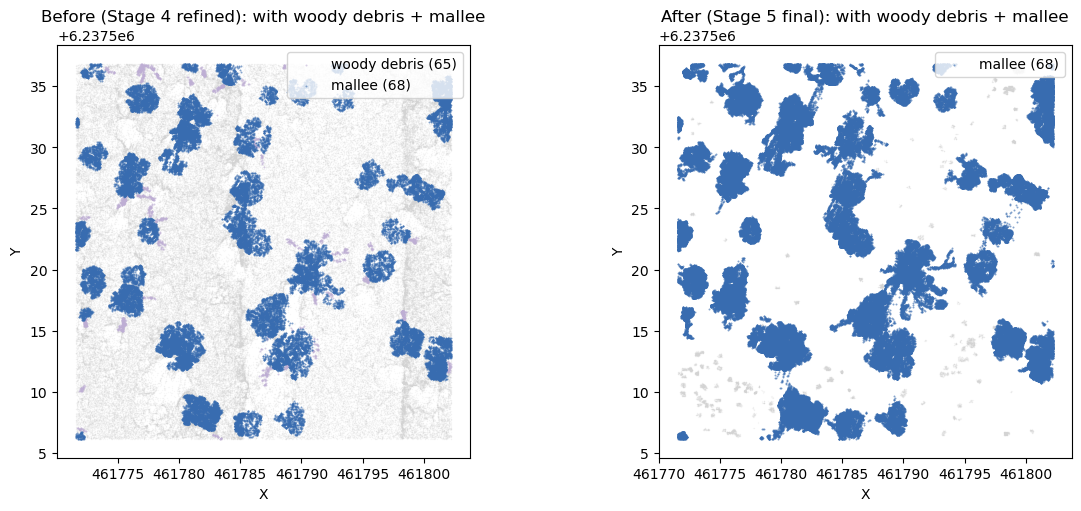

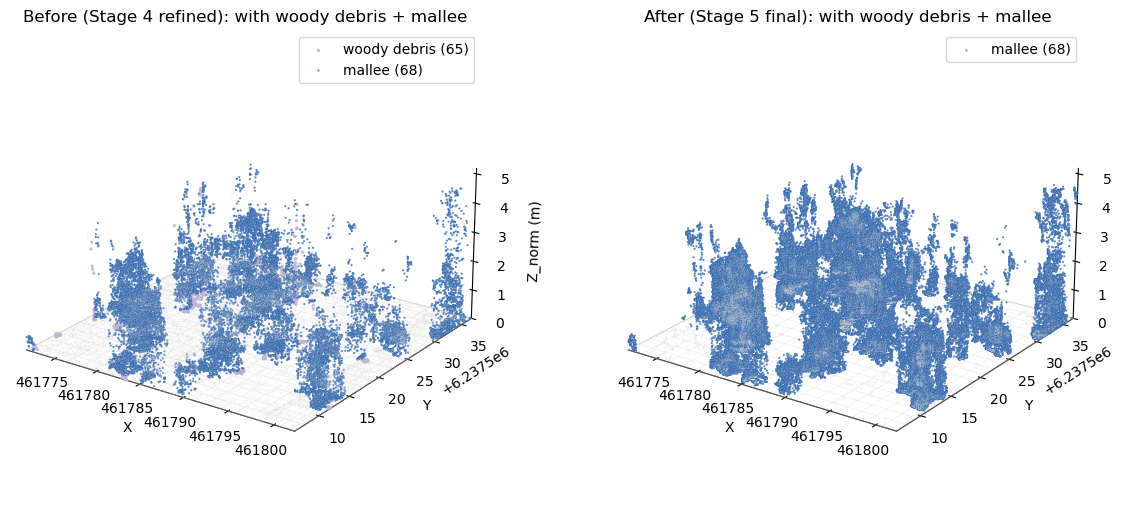

In [19]:
# --- Stage 5: Height-based consolidation and crown-level consistency ---
import numpy as np
import matplotlib.pyplot as plt

from fvc3dstruct.height_stats import auto_mallee_min_height

mallee_min = auto_mallee_min_height(height_ranges)
print(f"Using mallee_min height: {mallee_min:.2f} m")

# Before Stage 5 = Stage 4 refined labels
classification_before = refined_cls.copy()
zn_arr = zn

# Optional: compute crown instance IDs for all points using the watershed crown grid
label_grid = None
grid_min_x = None
grid_min_y = None
grid_res_ws = 0.10

if "labels" in globals() and isinstance(labels, np.ndarray) and labels.ndim == 2:
    label_grid = labels
    grid_min_x = min_x_ws
    grid_min_y = min_y_ws
elif "labels2" in globals() and isinstance(labels2, np.ndarray) and labels2.ndim == 2:
    label_grid = labels2
    grid_min_x = min_x_ws2
    grid_min_y = min_y_ws2

instance_ids = np.zeros(len(classification_before), dtype=np.uint16)
if label_grid is not None and label_grid.max() > 0:
    ix = np.clip(((las_z.x - grid_min_x) / grid_res_ws).astype(int), 0, label_grid.shape[1] - 1)
    iy = np.clip(((las_z.y - grid_min_y) / grid_res_ws).astype(int), 0, label_grid.shape[0] - 1)
    instance_ids = label_grid[iy, ix].astype(np.uint16)
else:
    print("No watershed crown grid found; skipping crown-level consistency rules")

# --- Consolidation rules (example heuristics) ---
classification_stage5 = classification_before.copy()

# Merge high woody debris (65) -> mallee (68); drop low woody debris points
MERGE_65_TO_68_ZNORM = 0.5
mask_65 = classification_stage5 == 65
mask_65_high = mask_65 & (zn_arr > MERGE_65_TO_68_ZNORM)
mask_65_low = mask_65 & (zn_arr < MERGE_65_TO_68_ZNORM)
classification_stage5[mask_65_high] = 68

# Drop low woody debris points from the cloud entirely
keep_mask_base = ~mask_65_low
classification_kept = classification_stage5[keep_mask_base]
zn_kept = zn_arr[keep_mask_base]
instance_ids_kept = instance_ids[keep_mask_base]

# Filter class-0 points, but keep sufficiently high points
HIGH_Z_KEEP = 1.3
keep_final = (classification_kept != 0) | (zn_kept >= HIGH_Z_KEEP)

classification_final = classification_kept[keep_final]
zn_final = zn_kept[keep_final]
instance_ids_final = instance_ids_kept[keep_final]

# Promote high class-0 -> mallee (via intermediate 65), then collapse 65 -> 68
promote = (classification_final == 0) & (zn_final >= HIGH_Z_KEEP)
classification_final[promote] = 65
classification_final[classification_final == 65] = 68

n_kept = len(classification_final)
print(f"Kept {n_kept:,}/{len(classification_before):,} points after filtering ({100.0*n_kept/len(classification_before):.1f}%)")
print(f"Dropped low woody debris points (65 below {MERGE_65_TO_68_ZNORM} m): {mask_65_low.sum():,}")

# Crown-level consistency + height rule (only if crown instances exist)
if instance_ids_final.max() > 0:
    n_reclassified = 0
    for crown_id in range(1, int(instance_ids_final.max()) + 1):
        in_crown = instance_ids_final == crown_id
        if in_crown.sum() == 0:
            continue
        crown_classes = classification_final[in_crown]
        n_mallee = (crown_classes == 68).sum()
        n_total = len(crown_classes)
        if n_total > 0 and (n_mallee / n_total) > 0.5:
            is_non_mallee = in_crown & (classification_final != 68)
            n_converted = is_non_mallee.sum()
            if n_converted > 0:
                classification_final[is_non_mallee] = 68
                n_reclassified += n_converted
    if n_reclassified > 0:
        print(f"Reclassified {n_reclassified:,} points to mallee (68) via crown majority vote")

    high_in_crown = (instance_ids_final > 0) & (zn_final >= mallee_min) & (classification_final != 68)
    if high_in_crown.any():
        n_reclassified_height = int(high_in_crown.sum())
        classification_final[high_in_crown] = 68
        print(f"Reclassified {n_reclassified_height:,} high crown points -> 68 (height rule)")

print(f"Final labeled points: {(classification_final > 0).sum():,}/{len(classification_final):,}")

# --- Shared arrays for visualization ---
x_all = np.asarray(las_z.x)
y_all = np.asarray(las_z.y)

x_kept = x_all[keep_mask_base]
y_kept = y_all[keep_mask_base]
x_final = x_kept[keep_final]
y_final = y_kept[keep_final]

def _sample_idx(n: int, max_points: int, seed: int) -> np.ndarray:
    if n <= max_points:
        return np.arange(n, dtype=int)
    rng = np.random.default_rng(seed)
    return rng.choice(n, size=max_points, replace=False)

def _get_class_color(class_value: int, fallback: str) -> str:
    if "class_order" in globals() and "class_colors" in globals():
        try:
            return class_colors[class_order.index(class_value)]
        except Exception:
            return fallback
    return fallback

woody_color = _get_class_color(65, "tab:orange")
mallee_color = _get_class_color(68, "tab:brown")

# --- Visualization (2D): keep previous before/after XY view ---
max_points_2d = 200_000
idx_before_2d = _sample_idx(len(classification_before), max_points=max_points_2d, seed=10)
idx_after_2d = _sample_idx(len(classification_final), max_points=max_points_2d, seed=11)

x2_b = x_all[idx_before_2d]
y2_b = y_all[idx_before_2d]
cls2_b = classification_before[idx_before_2d]

x2_a = x_final[idx_after_2d]
y2_a = y_final[idx_after_2d]
cls2_a = classification_final[idx_after_2d]

fig2, (ax2_before, ax2_after) = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

def _plot_xy(ax, x, y, cls, title: str):
    ax.scatter(x, y, s=1, c="lightgray", alpha=0.15, linewidths=0)
    m65 = cls == 65
    m68 = cls == 68
    if m65.any():
        ax.scatter(x[m65], y[m65], s=2, c=woody_color, alpha=0.6, linewidths=0, label="woody debris (65)")
    if m68.any():
        ax.scatter(x[m68], y[m68], s=2, c=mallee_color, alpha=0.6, linewidths=0, label="mallee (68)")
    ax.set_title(title)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_aspect("equal", adjustable="box")
    handles, labels = ax.get_legend_handles_labels()
    if len(handles) > 0:
        ax.legend(loc="upper right")

_plot_xy(ax2_before, x2_b, y2_b, cls2_b, "Before (Stage 4 refined): with woody debris + mallee")
_plot_xy(ax2_after, x2_a, y2_a, cls2_a, "After (Stage 5 final): with woody debris + mallee")
plt.show()

# --- Visualization (3D): replicate the same before/after layout as the 2D view ---
max_points_3d = 80_000
idx_before = _sample_idx(len(classification_before), max_points=max_points_3d, seed=0)
idx_after = _sample_idx(len(classification_final), max_points=max_points_3d, seed=1)

x_b = x_all[idx_before]
y_b = y_all[idx_before]
z_b = zn_arr[idx_before]
cls_b = classification_before[idx_before]

x_a = x_final[idx_after]
y_a = y_final[idx_after]
z_a = zn_final[idx_after]
cls_a = classification_final[idx_after]

# Use full-extent limits (not just the subsample) so 3D matches the 2D framing
x_min = float(np.nanmin(np.concatenate([x_all, x_final])))
x_max = float(np.nanmax(np.concatenate([x_all, x_final])))
y_min = float(np.nanmin(np.concatenate([y_all, y_final])))
y_max = float(np.nanmax(np.concatenate([y_all, y_final])))
z_min = 0.0
z_max = float(np.nanmax(np.concatenate([zn_arr, zn_final])))

def _add_reference_mesh(ax):
    # Cleaner style: no side walls, just a nice floor grid and "white" look
    mesh_color = "#AAAAAA"
    lw = 0.5
    a = 0.2

    n_grid = 20
    gx = np.linspace(x_min, x_max, n_grid)
    gy = np.linspace(y_min, y_max, n_grid)

    # Ground plane (z = 0) with a slightly denser grid
    GX, GY = np.meshgrid(gx, gy)
    GZ = np.zeros_like(GX)
    
    # Draw grid lines explicitly (better control than plot_wireframe)
    for i in range(n_grid):
        ax.plot([gx[0], gx[-1]], [gy[i], gy[i]], [0, 0], color=mesh_color, alpha=a, linewidth=lw)
        ax.plot([gx[i], gx[i]], [gy[0], gy[-1]], [0, 0], color=mesh_color, alpha=a, linewidth=lw)

    # Bounding box edges (bottom only to ground scene)
    edge_a = 0.4
    xs = [x_min, x_max]
    ys = [y_min, y_max]
    ax.plot(xs, [ys[0], ys[0]], [0, 0], color=mesh_color, alpha=edge_a, linewidth=lw*1.5)
    ax.plot(xs, [ys[1], ys[1]], [0, 0], color=mesh_color, alpha=edge_a, linewidth=lw*1.5)
    ax.plot([xs[0], xs[0]], ys, [0, 0], color=mesh_color, alpha=edge_a, linewidth=lw*1.5)
    ax.plot([xs[1], xs[1]], ys, [0, 0], color=mesh_color, alpha=edge_a, linewidth=lw*1.5)

def _plot_3d(ax, x, y, z, cls, title: str):
    # Clean axis panes for a "white background" look
    ax.xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.zaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.grid(False)  # We drew our own clean floor grid

    # Background cloud (faint)
    ax.scatter(x, y, z, s=0.3, c="#DDDDDD", alpha=0.1, linewidths=0, depthshade=False)

    m65 = cls == 65
    m68 = cls == 68
    if m65.any():
        ax.scatter(x[m65], y[m65], z[m65], s=6, c=woody_color, alpha=0.8, linewidths=0, label="woody debris (65)", depthshade=True)
    if m68.any():
        ax.scatter(x[m68], y[m68], z[m68], s=2.5, c=mallee_color, alpha=0.8, linewidths=0, label="mallee (68)", depthshade=True)

    _add_reference_mesh(ax)
    ax.set_title(title)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z_norm (m)")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_zlim(z_min, z_max)

    x_range = max(1e-9, x_max - x_min)
    y_range = max(1e-9, y_max - y_min)
    z_range = max(1e-9, z_max - z_min)
    z_exag = 3.0 # Slightly reduced from 4.0 to look more natural
    try:
        ax.set_box_aspect((x_range, y_range, z_range * z_exag))
    except Exception:
        pass

    ax.view_init(elev=22, azim=-55) # Slightly higher angle to see the "floor" better

# Match the 2D layout: 1×2 before/after
fig = plt.figure(figsize=(12, 5), constrained_layout=True)
ax_before = fig.add_subplot(1, 2, 1, projection="3d")
ax_after = fig.add_subplot(1, 2, 2, projection="3d")

_plot_3d(ax_before, x_b, y_b, z_b, cls_b, "Before (Stage 4 refined): with woody debris + mallee")
if len(ax_before.get_legend_handles_labels()[0]) > 0:
    ax_before.legend(loc="upper right")

_plot_3d(ax_after, x_a, y_a, z_a, cls_a, "After (Stage 5 final): with woody debris + mallee")
if len(ax_after.get_legend_handles_labels()[0]) > 0:
    ax_after.legend(loc="upper right")

plt.show()

## Stage 6 – Output generation

**Purpose:** Produce analysis-ready 3D products for mapping, QC, and downstream 3D learning.

**Key operations:**  
- Export LAS 1.4 (Point Format 6) with final class + `treeID`  
- Write full fused (gap-aware) point cloud  
- Optionally generate vegetation-only products / masks for visualisation and evaluation

**Output:** Final 3D vegetation structure datasets.

In [20]:
# --- Stage 6: Output products (written by the pipeline) ---
# This cell defines the expected filenames and (optionally) loads the veg-only LAS for inspection.
from pathlib import Path

out_dir = OUTPUT_BASE_DIR if "OUTPUT_BASE_DIR" in globals() else nb_out_dir
out_veg = Path(out_dir) / f"znorm_3Dlabels_{tile_id}.las"
out_full_fused = out_veg.with_name(out_veg.stem + "_full_fused" + out_veg.suffix)
out_veg_mask = out_veg.with_name(out_veg.stem + "_veg_mask.npy")

print("Expected outputs:")
print(f"  Veg-only LAS      : {out_veg}")
print(f"  Full fused LAS    : {out_full_fused}  (optional)")
print(f"  Veg mask (NPY)    : {out_veg_mask}    (optional)")

if out_veg.exists():
    las_out = laspy.read(out_veg)
    cls = np.asarray(las_out.classification, dtype=np.uint8)
    has_treeid = "treeID" in las_out.point_format.dimension_names
    print(f"\nLoaded veg-only LAS: {out_veg.name}")
    print(f"  Points: {len(las_out.points):,}")
    print(f"  Unique classes: {np.unique(cls)}")
    if has_treeid:
        tree_ids = np.asarray(las_out["treeID"], dtype=np.uint16)
        print(f"  Unique treeIDs (non-zero): {len(np.unique(tree_ids[tree_ids > 0]))}")
else:
    print("\n(No outputs yet. Run the pipeline cell below first.)")

Expected outputs:
  Veg-only LAS      : /home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class/notebooks/outputs/znorm_3Dlabels_109.las
  Full fused LAS    : /home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class/notebooks/outputs/znorm_3Dlabels_109_full_fused.las  (optional)
  Veg mask (NPY)    : /home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class/notebooks/outputs/znorm_3Dlabels_109_veg_mask.npy    (optional)

(No outputs yet. Run the pipeline cell below first.)


In [21]:
# ========================================
# Run the full Option A pipeline (Table-3 stages 1–6)
# ========================================
# Choose run mode: 'single' or 'folder'
RUN_MODE = "folder"  # set to "single" to only process tile_id

# Output directory (toggle based on site)
if SITE_NAME == "site1_DD0001":
    OUTPUT_BASE_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/3d_structure_mask_malleid")
elif SITE_NAME == "site2_DD0011":
    OUTPUT_BASE_DIR = Path("/data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/3d_structure_mask_malleid")
else:
    OUTPUT_BASE_DIR = nb_out_dir  # fallback to notebook outputs

OUTPUT_BASE_DIR.mkdir(parents=True, exist_ok=True)

# Main pipeline output is veg-only LAS (non-zero classes only)
out_veg = None

# Optional config overrides (edit as needed)
config = {
    # --- Stage 2: voxel baseline ---
    # "voxel_size_xy": 0.10,
    # "voxel_size_z": 0.10,

    # --- Stage 4: polar refinement ---
    # "r_bin": 0.10,
    # "theta_bin_deg": 10.0,
    # "min_conf": 0.3,
    # "min_flip_ratio": 1.5,

    # --- Stage 3: watershed crown detection ---
    # Set to "auto" to estimate from canopy spacing
    "min_tree_dist": "auto",   # or numeric meters (e.g., 1.5, 2.5, 3.0)
    "smoothing_sigma": "auto", # or numeric pixels (e.g., 1.0, 1.6, 2.0)

    # --- Stage 6: output generation ---
    "write_full_fused": True,   # writes *_full_fused.las (gap-aware full cloud)
    "write_veg_mask_npy": True, # writes *_veg_mask.npy aligned to the full cloud
    # "save_stage_outputs": True,
    # "stage_out_dir": str(OUTPUT_BASE_DIR / "stage_outputs"),
}

print(f"Processing mode: {RUN_MODE}")
print(f"Output directory: {OUTPUT_BASE_DIR}")
print("-" * 60)

if RUN_MODE == "single":
    out_veg = OUTPUT_BASE_DIR / f"znorm_3Dlabels_{tile_id}.las"
    print(f"Processing {SITE_NAME} tile {tile_id}...")
    print(f"Veg-only output LAS: {out_veg}")
    print("-" * 60)
    process_tile(
        z_path=z_path,
        s_path=s_path,
        out_path=out_veg,
        config=config,
    )
else:
    print(f"Batch processing all matched tiles in:\n  Z: {z_dir}\n  S: {s_dir}")
    print(f"Outputs → {OUTPUT_BASE_DIR}")

    z_files = sorted(z_dir.glob("z_norm_csf_tiles_multispectral.*.las"))
    s_files = sorted(s_dir.glob("mask_tiles_multispectral.*.las"))

    z_tiles = {f.stem.split(".")[-1]: f for f in z_files}
    s_tiles = {f.stem.split(".")[-1]: f for f in s_files}
    common_tiles = sorted(set(z_tiles.keys()) & set(s_tiles.keys()))

    if not common_tiles:
        print("⚠️ No matching tile pairs found!")
        outputs = []
    else:
        print(f"Found {len(common_tiles)} matching tile pairs")
        print(f"Tile IDs: {', '.join(common_tiles[:10])}{'...' if len(common_tiles) > 10 else ''}\n")

        outputs = []
        for tid in common_tiles:
            z_file = z_tiles[tid]
            s_file = s_tiles[tid]
            out_file = OUTPUT_BASE_DIR / f"znorm_3Dlabels_{tid}.las"

            print(f"Processing tile {tid}...")
            try:
                process_tile(
                    z_path=z_file,
                    s_path=s_file,
                    out_path=out_file,
                    config=config,
                )
                outputs.append(str(out_file))
                print(f"  ✅ Saved veg-only: {out_file.name}\n")
            except Exception as e:
                print(f"  ❌ Error: {e}\n")

    if outputs:
        out_veg = Path(outputs[-1])  # last processed output for downstream inspection
        print(f"\nUsing last processed veg-only output for inspection: {out_veg}")
    else:
        print("\nNo outputs produced in batch mode. Check input folders and patterns.")

print("\n" + "=" * 60)
print("✅ Pipeline completed successfully!" if out_veg else "⚠️  Pipeline did not produce an output to inspect.")
if out_veg:
    out_full_fused = out_veg.with_name(out_veg.stem + "_full_fused" + out_veg.suffix)
    out_veg_mask = out_veg.with_name(out_veg.stem + "_veg_mask.npy")
    print(f"Veg-only output LAS: {out_veg}")
    print(f"Full fused output LAS (if enabled): {out_full_fused}")
    print(f"Veg mask (if enabled): {out_veg_mask}")
print("=" * 60)

# Backward-compatible alias used by older notebook cells
out_full = out_veg

Processing mode: folder
Output directory: /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/3d_structure_mask_malleid
------------------------------------------------------------
Batch processing all matched tiles in:
  Z: /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/raster/z_norm/csf
  S: /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/mask/coreg/icp_top
Outputs → /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/3d_structure_mask_malleid
Found 10 matching tile pairs
Tile IDs: 109, 113, 182, 22, 26, 55, 65, 71, 93, 96

Processing tile 109...
📂 Processing z_norm_csf_tiles_multispectral.109
  Z_norm pts: 1,684,604, range: 0.00–5.18 m
  Struct pts: 394,106

1️⃣  Stage 1: Class height thresholding (robust priors)...


  ℹ️ Matched 394,106/394,106 structure pts to Z_norm
  ⚠️ Class 64 (Forb): only 0 pts → default (0.0, 0.4)
  Class 65 (Woody Debris): 0.00–0.23 m (n=8,823)
  Class 66 (Hummock): 0.00–0.13 m (n=10,349)
  Class 67 (Shrub): 0.00–0.31 m (n=1,826)
  Class 68 (Mallee): 0.01–1.56 m (n=353,432)
  → Mallee crown min height: 0.60 m

2️⃣  Stage 2: Cartesian voxel-based label transfer (baseline)...
  ✅ Voxels with non-zero structure class: 131,521
  ✅ Transferred labels to 432,204/1,684,604 Z_norm points (25.7%)

3️⃣  Stage 3: Mallee crown detection + instance assignment...
  → Auto params: min_tree_dist=0.80 m, smoothing_sigma=1.33 px
🌳 [Watershed] Identified 54 crowns (structure).
  → 405,889 points fall within 54 crowns

4️⃣  Stage 4: Crown-centric polar refinement with height priors...
  📊 Built statistics for 17,630 polar bins
  ✅ Updated 10,748/1,684,604 labels (0.6%)

5️⃣  Stage 5: Height-based consolidation + crown consistency...
  → Promoted 37,915 high unlabelled points → 68
  → Reclassi

/home/nvidia/micromamba/envs/fvc_structure/lib/python3.10/site-packages/scipy/ndimage/_measurements.py:1548: RuntimeWarning: invalid value encountered in divide
  results = [sum_labels(input * grids[dir].astype(float), labels, index) / normalizer


  ✅ Updated 155/69,962 labels (0.2%)

5️⃣  Stage 5: Height-based consolidation + crown consistency...
  → Promoted 1,407 high unlabelled points → 68
  → Reclassified 208 crown points → 68 via majority vote
  → Valid mallee treeIDs: 41

6️⃣  Stage 6: Output generation...
  → Vegetation-only: 24,574/69,962 points (35.1%)
✅ Wrote veg-only LAS: znorm_3Dlabels_182.las
✅ Wrote full fused LAS: znorm_3Dlabels_182_full_fused.las
✅ Wrote veg mask: znorm_3Dlabels_182_veg_mask.npy
   TreeIDs (unique, non-zero): 41

  ✅ Saved veg-only: znorm_3Dlabels_182.las

Processing tile 22...
📂 Processing z_norm_csf_tiles_multispectral.22
  Z_norm pts: 2,878,830, range: 0.00–4.36 m
  Struct pts: 1,123,666

1️⃣  Stage 1: Class height thresholding (robust priors)...
  ℹ️ Matched 1,123,666/1,123,666 structure pts to Z_norm
  ⚠️ Class 64 (Forb): only 0 pts → default (0.0, 0.4)
  Class 65 (Woody Debris): 0.00–0.04 m (n=166,856)
  Class 66 (Hummock): 0.00–0.11 m (n=248,484)
  ⚠️ Class 67 (Shrub): only 0 pts → defaul

Inspecting: /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/3d_structure_mask_malleid/znorm_3Dlabels_96.las
Points: 575,857
Bounds: X[461832.95, 461863.66]  Y[6237536.81, 6237567.53]  Z[60.40, 65.48]

Class distribution in output:
  Class  66:    74916 pts ( 13.0 %)
  Class  67:     2869 pts (  0.5 %)
  Class  68:   498072 pts ( 86.5 %)

Non-zero treeIDs: 57


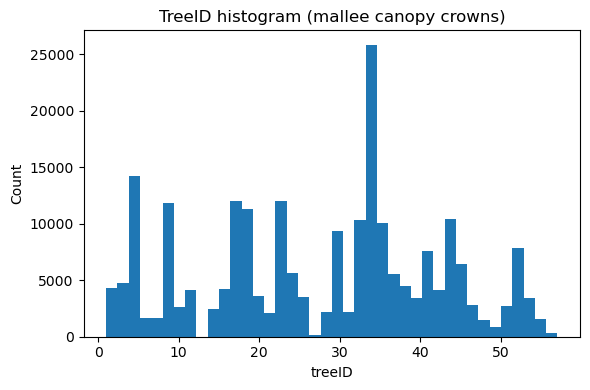

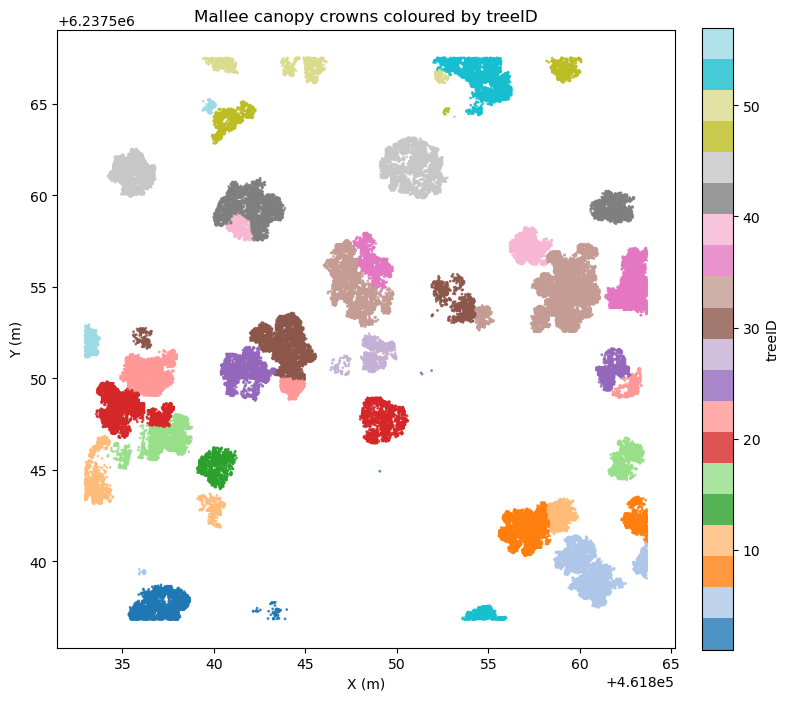

In [23]:
# --- QC: Inspect final output (classes + treeID) ---
from pathlib import Path

out_path = None
if "out_veg" in globals() and out_veg:
    out_path = Path(out_veg)
elif "out_full" in globals() and out_full:
    out_path = Path(out_full)

if not out_path or not out_path.exists():
    raise FileNotFoundError("No output LAS found to inspect. Run the pipeline cell first.")

las_out = laspy.read(out_path)
cls = np.asarray(las_out.classification, dtype=np.uint8)
has_treeid = "treeID" in las_out.point_format.dimension_names
tree_ids = np.asarray(las_out["treeID"], dtype=np.uint16) if has_treeid else None

print(f"Inspecting: {out_path}")
print(f"Points: {len(las_out.points):,}")
print(f"Bounds: X[{las_out.header.mins[0]:.2f}, {las_out.header.maxs[0]:.2f}]  Y[{las_out.header.mins[1]:.2f}, {las_out.header.maxs[1]:.2f}]  Z[{las_out.header.mins[2]:.2f}, {las_out.header.maxs[2]:.2f}]")

# Class distribution
unique, counts = np.unique(cls, return_counts=True)
print("\nClass distribution in output:")
for u, c in zip(unique, counts):
    pct = 100.0 * c / len(cls)
    print(f"  Class {u:3d}: {c:8d} pts ({pct:5.1f} %)")

if tree_ids is None:
    print("\nNo `treeID` dimension found in this LAS.")
else:
    valid_trees = tree_ids[tree_ids > 0]
    print(f"\nNon-zero treeIDs: {len(np.unique(valid_trees)) if valid_trees.size else 0}")
    if valid_trees.size > 0:
        plt.figure(figsize=(6, 4))
        plt.hist(valid_trees, bins=40)
        plt.xlabel("treeID")
        plt.ylabel("Count")
        plt.title("TreeID histogram (mallee canopy crowns)")
        plt.tight_layout()
        plt.show()

        # Quick 2D scatter of mallee crown points coloured by treeID
        is_mallee = cls == 68
        mask = is_mallee & (tree_ids > 0)
        if mask.any():
            idx = np.where(mask)[0]
            if idx.size > 80000:
                idx = np.random.choice(idx, size=80000, replace=False)
            xs = las_out.x[idx]
            ys = las_out.y[idx]
            tids = tree_ids[idx]

            fig, ax = plt.subplots(figsize=(8, 8))
            sc = ax.scatter(xs, ys, c=tids, s=1, cmap="tab20", alpha=0.8)
            ax.set_title("Mallee canopy crowns coloured by treeID", fontsize=12)
            ax.set_xlabel("X (m)")
            ax.set_ylabel("Y (m)")
            ax.set_aspect("equal", adjustable="box")
            plt.colorbar(sc, ax=ax, label="treeID", fraction=0.046, pad=0.04)
            plt.tight_layout()
            plt.show()
        else:
            print("No (class 68 + treeID>0) points to scatter-plot in this tile.")
    else:
        print("No non-zero treeIDs in this tile (check thresholds / watershed).")